# 1. Introduction

Ce notebook construit et évalue des modèles de prévision des résultats des courses cyclistes amateurs des catégories Access (FFC), en Bretagne et en Pays de la Loire. L'objectif final est d'afficher dans le dashboard, pour une course donnée, les coureurs les plus susceptibles de gagner, de faire un podium, un top 5 ou un top 10, avec leur probabilité.

**Données.** Résultats des courses depuis 2023 (tables `races` et `rankings` du dernier instantané de la base).

**Principes de l'évaluation.**

- Une course est prévue uniquement avec les résultats antérieurs à son jour : aucun résultat du jour ni ultérieur n'est utilisé.
- Les engagés d'une course passée sont ses coureurs classés : les abandons sont absents, limite acceptée.
- Seules les courses de plus de 20 classés sont évaluées (voir 3.3).
- Les réglages sont choisis sur la **période de réglage** (avril 2023 à fin 2025) ; 2026 est réservée à une **mesure finale unique** (période de test), pour ne pas retenir des réglages favorisés par le hasard des courses évaluées.

**Métriques de classement**, calculées course par course puis moyennées :

- **précision@20** : part des 20 coureurs classés en tête par la prévision qui finissent réellement dans le top 20 ;
- **NDCG@10** : qualité de l'ordre des 10 premiers prévus, entre 0 et 1, les premières places pesant le plus ;
- **Spearman** : corrélation entre l'ordre prévu et l'ordre réel de tout le peloton, entre −1 et 1.

**Démarche.** Une baseline simple, la forme récente, sert de référence (section 3). Viennent ensuite un modèle de notes de niveau, OpenSkill (section 4), une régression logistique (section 5) et XGBoost (section 6), tous pour la cible top 20. La section 7 étend le meilleur modèle aux quatre cibles du dashboard, avec des métriques adaptées aux listes affichées et à la qualité des probabilités. La section 8 reprend la chaîne retenue avec les fonctions du paquet `access_it`, la section 9 conclut.

# 2. Préparation

## 2.1 Modules

In [76]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from access_it.analytics.ranking_tools import select_recent_results
from access_it.config import get_settings
from access_it.etl.extract.cache import SNAPSHOTS_DIR
from access_it.export.s3 import download_latest_snapshot
from access_it.export.snapshot import read_snapshot_zip
from access_it.features.baseline import rank_by_recent_form
from access_it.features.ratings import rate_riders_on_race_eve
from access_it.model.evaluation import add_predicted_rank, evaluate_forecasts
from access_it.model.metrics import compute_race_metrics, METRICS, summarize_metrics

# Static images, so that the figures are shown on GitHub
pio.renderers.default = "png"
pio.renderers["png"].width = 1000

## 2.2 Constantes

Paramètres de la forme récente de la première version de la baseline : top 20, 10 dernières courses au plus, fenêtre de 6 mois.

In [2]:
TOP_N = 20
LAST_RACES = 10
WINDOW_MONTHS = 6

## 2.3 Chargement des données

Le dernier instantané de la base est téléchargé depuis le stockage S3, puis lu. `LAST_SEASON` est la saison de la course la plus récente.

In [ ]:
settings = get_settings()
bucket = settings.s3_bucket
snapshot_path = download_latest_snapshot(bucket, SNAPSHOTS_DIR)

In [4]:
tables = read_snapshot_zip(snapshot_path)
races = tables["races"]
rankings = tables["rankings"]

In [5]:
LAST_SEASON = pd.to_datetime(races["race_date"], format="%Y-%m-%d").dt.year.max()
print(f"LAST_SEASON: {LAST_SEASON}")

LAST_SEASON: 2026


# 3. Baseline : forme récente

La baseline classe les engagés d'une course selon leur **taux de top 20** sur leurs dernières courses (forme récente), calculé la veille de la course. À taux égal, les coureurs sont départagés par leurs meilleures places successives, puis par identifiant. Elle sert de référence à battre par tous les modèles.

## 3.1 Production des prévisions

Toutes les courses sont prévues à partir du 1er avril 2023 : les courses de janvier à mars 2023 servent seulement au calcul de la forme récente.

In [6]:
%%time
forecasts = rank_by_recent_form(
    races=races,
    rankings=rankings,
    last_season=LAST_SEASON,
    first_race_date="2023-04-01",
    top_n=TOP_N,
    last_races=LAST_RACES,
    window_months=WINDOW_MONTHS
)

CPU times: user 6.25 s, sys: 227 ms, total: 6.48 s
Wall time: 7.59 s


## 3.2 Contrôle des prévisions

In [7]:
forecasts.head()

,race_id,race_date,rider_id,finish_rank,nb_races_used,nb_top_n,top_n_rate,predicted_rank
0,4895ed36be431ee2,2023-04-01,cd3adc138151a731,15,1,1,1.0,1
1,4895ed36be431ee2,2023-04-01,3b32ce348dd1ce4d,12,3,3,1.0,2
2,4895ed36be431ee2,2023-04-01,64fa0b15814b30b8,11,4,4,1.0,3
3,4895ed36be431ee2,2023-04-01,06dedd30259dba78,30,3,3,1.0,4
4,4895ed36be431ee2,2023-04-01,8bc4783ad521fa43,7,1,1,1.0,5


### 3.2.1 Nombre de courses prévues

In [8]:
nb_forecasts = forecasts["race_id"].nunique()
print(f"Number of forecasts: {nb_forecasts}")

Number of forecasts: 1810


### 3.2.2 Nombre de classés par course

Number of races with less than 20 ranked riders: 189 (10.44%)


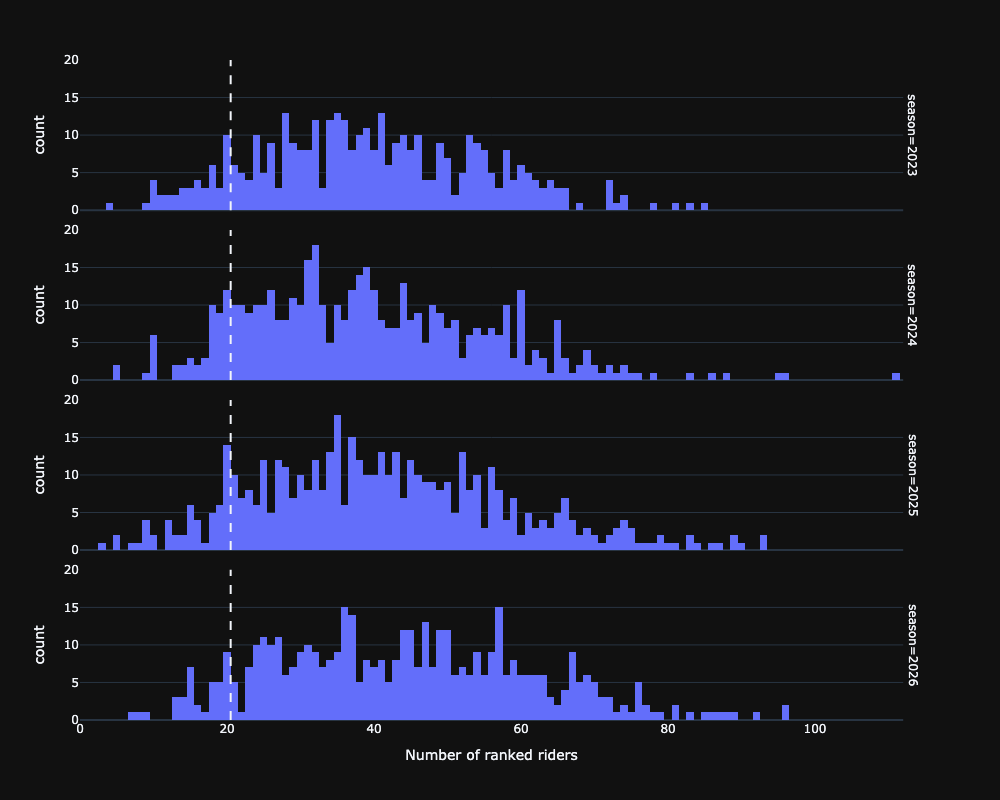

In [9]:
ranked_by_forecast = forecasts.groupby(by="race_id").agg(nb_ranked_riders=("rider_id", "size"), race_date=("race_date", "first"))
ranked_by_forecast["season"] = pd.to_datetime(ranked_by_forecast["race_date"], format="%Y-%m-%d").dt.year
ranked_by_forecast = ranked_by_forecast.sort_values(by="season")

races_below20riders = ranked_by_forecast[ranked_by_forecast["nb_ranked_riders"] <= 20].index
forecasts_above20riders = forecasts[~forecasts["race_id"].isin(races_below20riders)]

count = ranked_by_forecast["nb_ranked_riders"]
races_below20riders = count[races_below20riders].shape[0]
max_nb_ranked_riders = count.max()

print(f"Number of races with less than 20 ranked riders: {races_below20riders} ({races_below20riders / nb_forecasts * 100:.2f}%)")

fig = px.histogram(
    ranked_by_forecast,
    x="nb_ranked_riders",
    range_x=[0, max_nb_ranked_riders + 1],
    range_y=[0, 20],
    facet_row="season"
)
fig.update_traces(xbins=dict(start=count.min() - 0.5, end=count.max() + 0.5, size=1))
fig.add_vline(x=20.5, line_dash="dash")
fig.update_layout(xaxis_title="Number of ranked riders")
fig.update_layout(height=800)
fig.show()

#### Lecture

189 courses sur 1 810 (10,4 %) classent 20 coureurs ou moins, avec un pic à exactement 20 classés : de nombreux organisateurs arrêtent le classement au 20e. Dans ces courses, la liste des engagés connue se réduit au top 20 réel, ce qui fausse la tâche de prévision.

### 3.2.3 Part des coureurs sans forme récente

Un coureur sans course dans la fenêtre de la forme récente n'a aucune information : la baseline le classe en dernier.

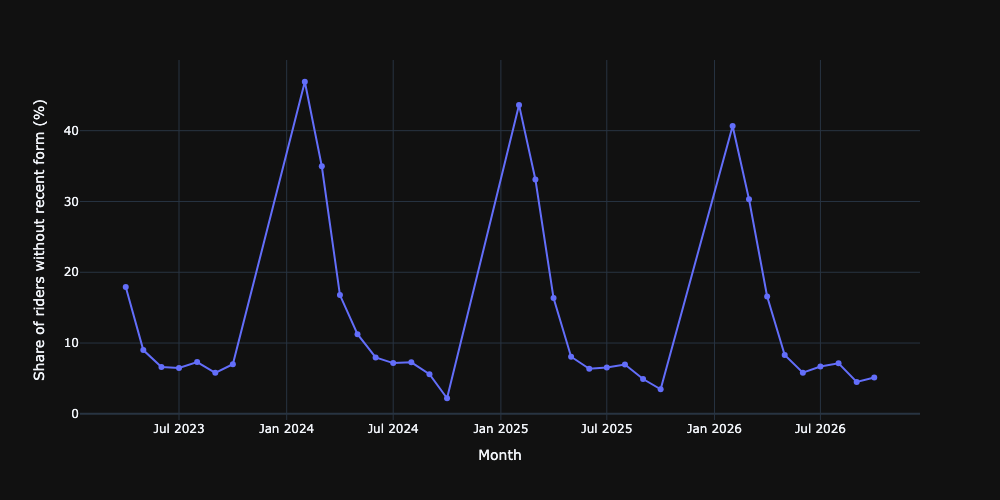

In [10]:
no_form = (
    forecasts.assign(month=forecasts["race_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")["nb_races_used"]
    .apply(lambda s: 100 * (s == 0).mean())
    .rename("share_without_form")
    .reset_index()
)
fig = px.line(no_form, x="month", y="share_without_form", markers=True)
fig.update_layout(xaxis_title="Month", yaxis_title="Share of riders without recent form (%)")
fig.show()

#### Lecture

La part des coureurs sans forme récente dépasse 40 % en février, vaut environ 16 à 18 % en avril, passe sous 10 % dès mai et descend à 3-5 % en septembre-octobre. Le début de saison est la période la plus difficile à prévoir : avec une fenêtre de 6 mois, la forme d'un coureur au printemps ne repose que sur la fin de la saison précédente.

## 3.3 Calcul des scores

Les métriques sont calculées sur toutes les courses, puis sur les seules courses de plus de 20 classés.

In [11]:
race_metrics = compute_race_metrics(forecasts)
race_metrics_above20riders = compute_race_metrics(forecasts_above20riders)

In [12]:
race_metrics_above20riders.head()

,race_id,race_date,precision_at_20,ndcg_at_10,spearman
0,4895ed36be431ee2,2023-04-01,0.65,0.406802,0.273887
1,82c40f3654b90e60,2023-04-01,0.90,0.834579,0.573077
2,0d3c4d5d3c60fe45,2023-04-02,0.75,0.704232,0.482955
3,25053b296c671129,2023-04-02,0.60,0.447469,0.107490
4,37366d2f851049f4,2023-04-02,0.50,0.280243,0.172577


In [13]:
metrics_summary = summarize_metrics(race_metrics)
print(metrics_summary.head())

            metric      mean  nb_races
0  precision_at_20  0.662862      1621
1       ndcg_at_10  0.580522      1810
2         spearman  0.382764      1810


In [14]:
metrics_summary_above20riders = summarize_metrics(race_metrics_above20riders)
print(metrics_summary_above20riders.head())

            metric      mean  nb_races
0  precision_at_20  0.662862      1621
1       ndcg_at_10  0.550664      1621
2         spearman  0.389293      1621


#### Lecture

- **La précision@20 est identique dans les deux cas** : elle n'est calculée que sur les courses de plus de 20 classés. En moyenne, 66 % des 20 coureurs prévus finissent dans le top 20, soit environ 13 sur 20.
- **Le NDCG@10 baisse de 0,03 sans les courses de 20 classés ou moins** : dans ces courses, peu de coureurs sont à ordonner et tous les engagés connus sont dans le top 20, ce qui gonfle le score.
- **Le Spearman ne varie presque pas** (0,38 contre 0,39) : la corrélation entre ordre prévu et ordre réel est positive mais modérée.

#### Courses retenues pour la suite

Toutes les évaluations portent désormais sur les seules courses de plus de 20 classés : les trois métriques portent ainsi sur les mêmes courses, et les classements arrêtés au 20e sont écartés.

## 3.4 Répartition des scores

### 3.4.1 Répartition par course

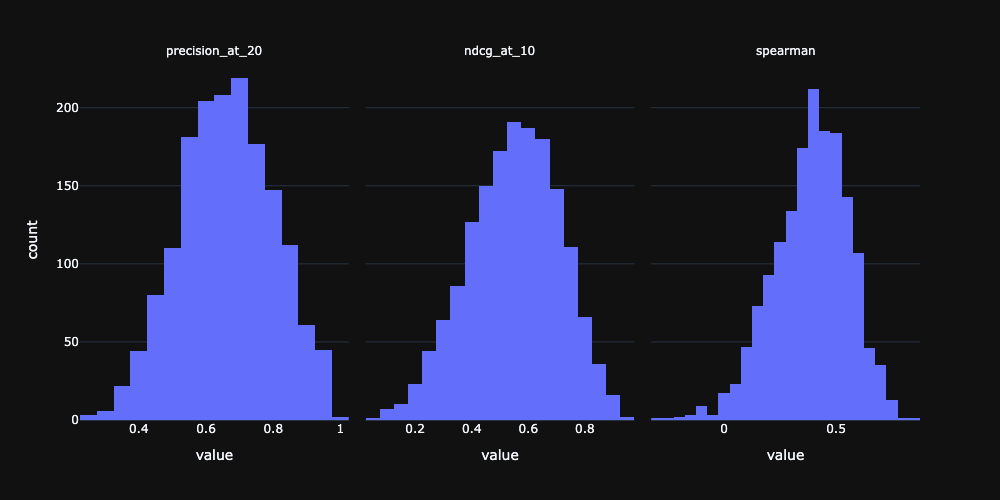

In [15]:
long_metrics = race_metrics_above20riders.melt(
    id_vars=["race_id", "race_date"],
    value_vars=METRICS,
    var_name="metric",
    value_name="value",
).dropna(subset=["value"])

fig = px.histogram(
    long_metrics,
    x="value",
    facet_col="metric"
)
fig.update_traces(xbins=dict(start=-1.025, end=1.025, size=0.05))
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

#### Lecture

- **Précision@20** : distribution centrée sur 0,65, assez symétrique ; la moitié des courses est entre 0,55 et 0,75, soit 11 à 15 bons coureurs sur 20.
- **NDCG@10** : distribution centrée sur 0,55, un peu plus étalée (de 0,05 à 0,94).
- **Spearman** : distribution centrée sur 0,40 ; environ 1 % des courses ont une corrélation négative.

Chaque distribution n'a qu'un seul mode : la moyenne résume bien chaque métrique. La dispersion d'une course à l'autre est forte (écart type de 0,14 à 0,17), mais la moyenne sur 1 621 courses est précise (incertitude d'environ 0,004).

### 3.4.2 Évolution mensuelle

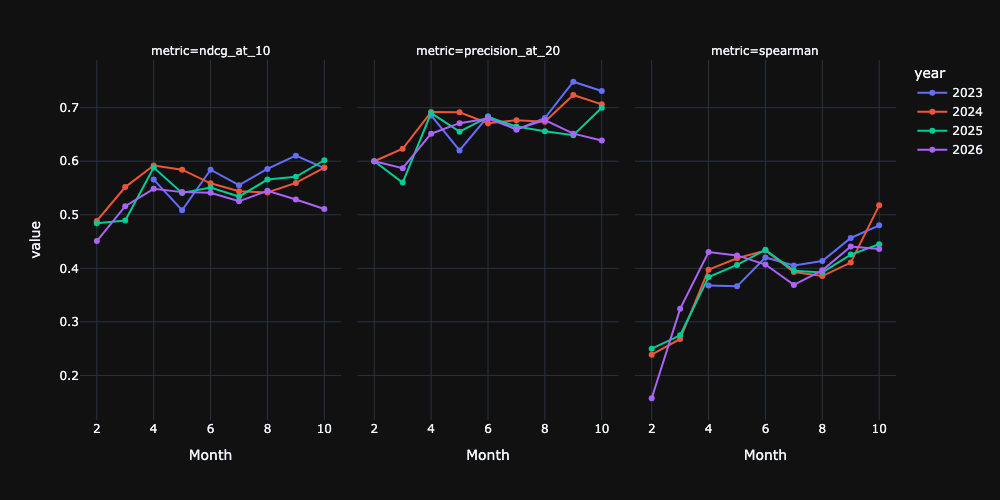

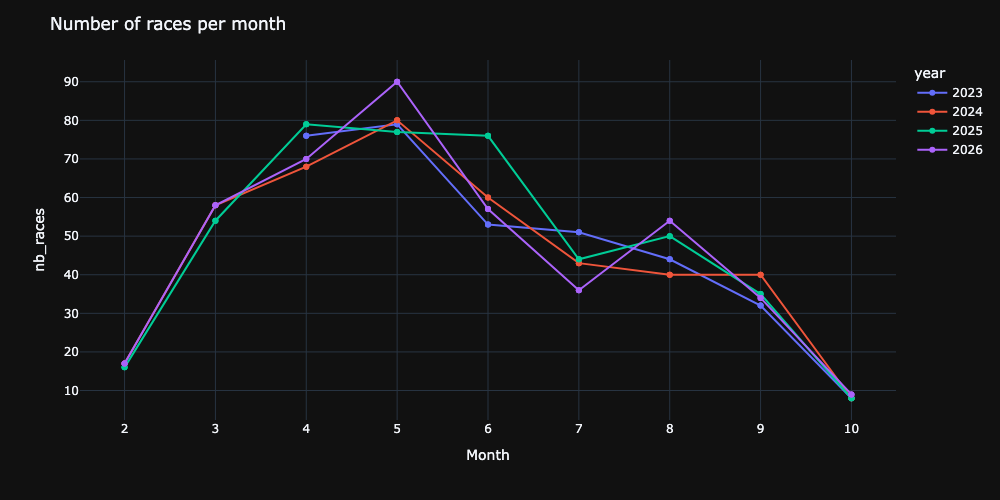

In [16]:
long_metrics["month"] = long_metrics["race_date"].dt.month
long_metrics["year"] = long_metrics["race_date"].dt.year
long_metrics_monthly_mean = (
    long_metrics
    .drop(columns="race_date")
    .groupby(by=["month", "year", "metric"])
    .agg(value=("value", "mean"), nb_races=("race_id", "size"))
    .reset_index(drop=False)
    .sort_values(by=["year", "month"])
)
fig1 = px.line(long_metrics_monthly_mean, x="month", y="value", color="year", facet_col="metric", markers=True)
fig1.update_xaxes(title_text="Month")
fig1.show()
fig2 = px.line(long_metrics_monthly_mean, x="month", y="nb_races", color="year", markers=True)
fig2.update_xaxes(title_text="Month")
fig2.update_layout(title="Number of races per month")
fig2.show()

#### Lecture

- **Le début de saison est nettement plus faible**, ce qui est cohérent avec la part de coureurs sans forme récente : Spearman de 0,16 à 0,25 en février et de 0,27 à 0,32 en mars, contre 0,37 à 0,45 d'avril à septembre ; le NDCG@10 et la précision@20 sont aussi au plus bas en février-mars.
- **D'avril à août, les scores sont stables**, d'un mois et d'une année à l'autre.
- **Février et octobre comptent peu de courses** : leurs valeurs sont peu fiables.
- **Le NDCG@10 baisse légèrement d'une année à l'autre** (environ 0,57 en 2023, 0,53 en 2026), sans cause identifiée.

#### Bilan

La baseline est une référence lisible : environ 13 bons coureurs sur 20 dans le top 20 prévu, et une corrélation de rang modérée (0,39). Son point faible est le début de saison, faute de forme récente. Une fenêtre plus longue pour la forme récente pourrait le réduire.

## 3.5 Sensibilité à la fenêtre de la forme récente

### 3.5.1 Cas étudiés

Quatre combinaisons de la fenêtre (6 ou 12 mois) et du nombre maximal de courses retenues (10 ou 20), évaluées sur les mêmes courses, sur toute l'année puis sur février et mars regroupés.

| Fenêtre | Courses au plus | Rôle                            |
|---------|-----------------|---------------------------------|
| 6 mois  | 10              | Référence actuelle              |
| 12 mois | 10              | Effet de la fenêtre seule       |
| 6 mois  | 20              | Effet du nombre de courses seul |
| 12 mois | 20              | Effet combiné                   |

In [17]:
results = []
for window_months, last_races in [(6, 10), (12, 10), (6, 20), (12, 20)]:
    forecasts = rank_by_recent_form(
        races=races,
        rankings=rankings,
        last_season=LAST_SEASON,
        first_race_date="2023-04-01",
        top_n=TOP_N,
        last_races=last_races,
        window_months=window_months
    )

    ranked_by_forecast = forecasts.groupby(by="race_id").agg(nb_ranked_riders=("rider_id", "size"), race_date=("race_date", "first"))
    races_above20riders = ranked_by_forecast[ranked_by_forecast["nb_ranked_riders"] > 20].index
    forecasts = forecasts[forecasts["race_id"].isin(races_above20riders)]
    for selection in ["all_year", "february+march"]:
        if selection == "all_year":
            mask = pd.Series(True, index=forecasts.index)
        else:
            mask = pd.to_datetime(forecasts["race_date"], format="%Y-%m-%d").dt.month.isin([2, 3])
        race_metrics = compute_race_metrics(forecasts[mask])
        metrics_summary = summarize_metrics(race_metrics)
        results.append(
            {
                "case": f"{window_months:d} mois, {last_races:d} courses",
                "selection": selection,
            }
            |
            metrics_summary.set_index("metric")["mean"].to_dict()
        )
results = pd.DataFrame(results).reset_index(drop=True)
print(results)

                  case       selection  precision_at_20  ndcg_at_10  spearman
0   6 mois, 10 courses        all_year         0.662862    0.550664  0.389293
1   6 mois, 10 courses  february+march         0.592955    0.509377  0.272465
2  12 mois, 10 courses        all_year         0.666317    0.554863  0.402580
3  12 mois, 10 courses  february+march         0.608409    0.518058  0.330579
4   6 mois, 20 courses        all_year         0.662924    0.548170  0.389016
5   6 mois, 20 courses  february+march         0.592955    0.509377  0.272465
6  12 mois, 20 courses        all_year         0.666996    0.550710  0.400671
7  12 mois, 20 courses  february+march         0.615227    0.517242  0.331568


In [18]:
long_results = results.melt(
    id_vars=["case", "selection"],
    value_vars=METRICS,
    var_name="metric",
    value_name="value",
).dropna(subset=["value"])
long_results

,case,selection,metric,value
0,"6 mois, 10 courses",all_year,precision_at_20,0.662862
1,"6 mois, 10 courses",february+march,precision_at_20,0.592955
2,"12 mois, 10 courses",all_year,precision_at_20,0.666317
3,"12 mois, 10 courses",february+march,precision_at_20,0.608409
4,"6 mois, 20 courses",all_year,precision_at_20,0.662924
5,"6 mois, 20 courses",february+march,precision_at_20,0.592955
6,"12 mois, 20 courses",all_year,precision_at_20,0.666996
7,"12 mois, 20 courses",february+march,precision_at_20,0.615227
8,"6 mois, 10 courses",all_year,ndcg_at_10,0.550664
9,"6 mois, 10 courses",february+march,ndcg_at_10,0.509377


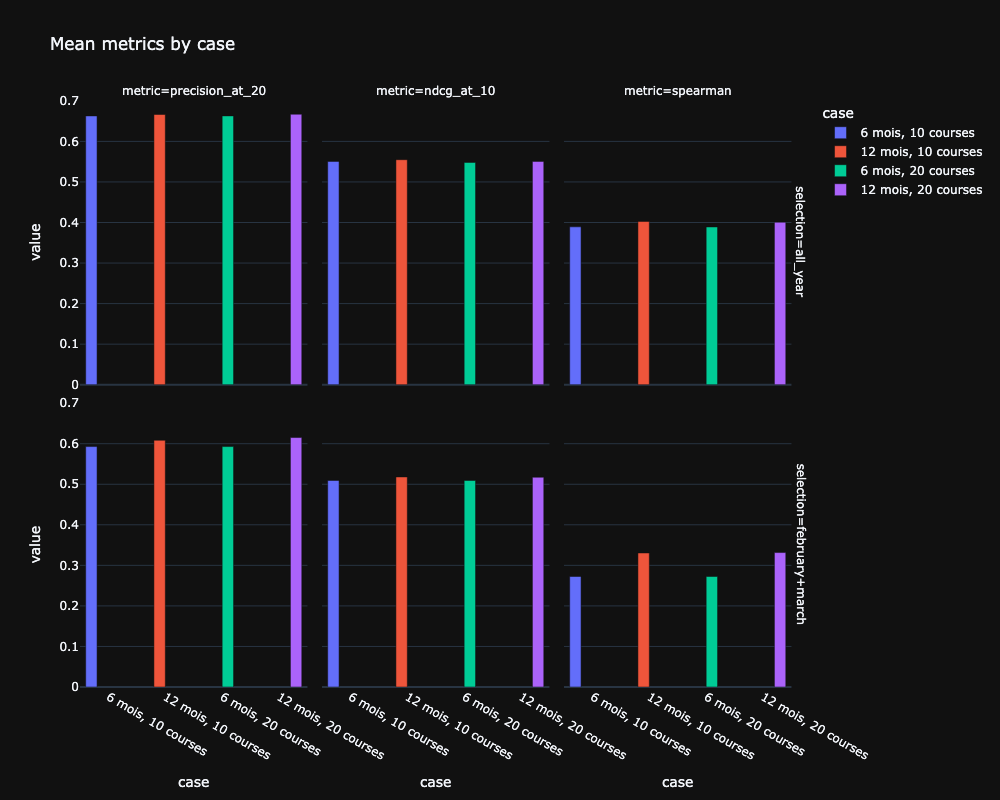

In [19]:
fig = px.bar(
    long_results,
    x="case",
    y="value",
    color="case",
    facet_row="selection",
    facet_col="metric",
    barmode="group",
    title="Mean metrics by case",
    # labels={"mean": "Mean metric value"},
    category_orders={
        "selection": ["all_year", "february+march"],
        "metric": METRICS,
    },
)
fig.update_layout(height=800)
fig.show()

### 3.5.2 Lecture des résultats

Le cas « 6 mois, 10 courses » redonne exactement les scores de la section 3.3 (0,663, 0,551 et 0,389).

**La fenêtre de 12 mois améliore la baseline, surtout en début de saison.** Écarts avec la référence, à 10 courses au plus :

| Métrique     | Toute l'année | Février et mars |
|--------------|---------------|-----------------|
| Précision@20 | +0,003        | +0,015          |
| NDCG@10      | +0,004        | +0,009          |
| Spearman     | +0,013        | +0,058          |

Le gain porte sur les coureurs qui ont peu couru récemment, donc surtout au printemps : en février et mars, le Spearman passe de 0,27 à 0,33.

**Passer à 20 courses n'apporte rien** : peu de coureurs ont plus de 10 courses dans la fenêtre, et les écarts restent minimes.

### 3.5.3 Décision

**La baseline retenue utilise une fenêtre de 12 mois et 10 courses au plus.** Ses scores sur les 1 621 courses de plus de 20 classés :

| Sélection       | Précision@20 | NDCG@10 | Spearman |
|-----------------|--------------|---------|----------|
| Toute l'année   | 0,666        | 0,555   | 0,403    |
| Février et mars | 0,608        | 0,518   | 0,331    |

## 3.6 Comparaison avec un ordre aléatoire

Les engagés d'une course passée étant ses classés, un ordre tiré au hasard atteint déjà en moyenne une précision@20 de 20 / n (n : nombre de classés). La moyenne de 20 / n sur les courses de plus de 20 classés indique la part de la précision qui vient de la seule taille du peloton.

In [20]:
n = ranked_by_forecast.loc[races_above20riders, "nb_ranked_riders"]
expected_random_precision = (20 / n).mean()
print(round(expected_random_precision, 3))

0.51


#### Lecture

La précision@20 attendue d'un ordre aléatoire est de 0,51, contre 0,666 pour la baseline : la forme récente apporte environ 0,16, soit environ 3 coureurs sur 20 (rapport de 1,31). La plupart des coureurs trouvés dans le top 20 s'expliquent par la taille du peloton, ce qui laisse une marge à un meilleur modèle.

## 3.7 Scores de référence

La baseline retenue (12 mois, 10 courses au plus) est recalculée avec les fonctions d'évaluation du paquet : d'abord sur toute la période (contrôle : mêmes scores qu'en 3.5.3), puis sur la période de réglage, sur toute l'année et sur février-mars. Ces derniers scores servent de référence aux sections suivantes ; la période de test (2026) n'est pas encore regardée.

In [21]:
baseline = rank_by_recent_form(
    races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01", window_months=12
)

# Check: whole period, must give the reference (0.666, 0.555, 0.403)
summarize_metrics(evaluate_forecasts(baseline, "2023-04-01", "2026-12-31"))

,metric,mean,nb_races
0,precision_at_20,0.666317,1621
1,ndcg_at_10,0.554863,1621
2,spearman,0.402580,1621


In [22]:
# References of the tuning period
summarize_metrics(evaluate_forecasts(baseline, "2023-04-01", "2025-12-31"))

,metric,mean,nb_races
0,precision_at_20,0.670610,1196
1,ndcg_at_10,0.563127,1196
2,spearman,0.401448,1196


In [23]:
# Only on February+March
summarize_metrics(evaluate_forecasts(baseline, "2023-04-01", "2025-12-31", months=[2, 3]))

,metric,mean,nb_races
0,precision_at_20,0.613793,145
1,ndcg_at_10,0.531298,145
2,spearman,0.329715,145


#### Lecture

Références de la baseline sur la période de réglage : précision@20 0,671, NDCG@10 0,563 et Spearman 0,401 sur toute l'année ; 0,614, 0,531 et 0,330 en février-mars.

# 4. OpenSkill : notes de niveau

OpenSkill attribue à chaque coureur une note composée d'un niveau estimé μ et d'une incertitude σ, mises à jour après chaque course d'après l'ordre d'arrivée (modèle de Plackett-Luce). Un nouveau coureur part de μ = 25 et σ = 8,33. Les notes sont lues la veille de chaque course, puis les coureurs sont classés selon un score μ − kσ : k = 0 correspond au niveau seul, k = 3 à une valeur prudente qui pénalise les coureurs encore mal connus.

## 4.1 Notes avec les réglages par défaut

In [24]:
%%time
ratings = rate_riders_on_race_eve(
    races=races,
    rankings=rankings,
    last_season=LAST_SEASON,
    first_race_date="2023-04-01",
)

CPU times: user 1.03 s, sys: 70.3 ms, total: 1.1 s
Wall time: 1.1 s


## 4.2 Contrôle des courses et des coureurs prévus

La baseline et OpenSkill doivent prévoir exactement les mêmes courses et les mêmes coureurs, pour que les différences de scores ne viennent que de la méthode.

In [25]:
keys = ["race_id", "rider_id"]
print(len(baseline))
assert len(ratings) == len(baseline)
assert (
    ratings[keys].sort_values(keys).reset_index(drop=True)
    .equals(baseline[keys].sort_values(keys).reset_index(drop=True))
)

74376


## 4.3 Classement selon μ − kσ

Évaluation sur la période de réglage pour k = 0, 1 et 3, avec la baseline comme référence.

In [26]:
TUNING_START, TUNING_END = "2023-04-01", "2025-12-31"
methods = {"baseline": baseline} | {
    f"openskill k={k}": add_predicted_rank(
        ratings.assign(score=ratings["mu"] - k * ratings["sigma"]), "score"
    )
    for k in (0, 1, 3)
}
rows = []
for name, forecasts in methods.items():
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": name, "selection": selection} | summary.set_index("metric")["mean"].to_dict())
comparison = pd.DataFrame(rows)
print(comparison.round(3))

          method       selection  precision_at_20  ndcg_at_10  spearman
0       baseline        all_year            0.671       0.563     0.401
1       baseline  february+march            0.614       0.531     0.330
2  openskill k=0        all_year            0.664       0.536     0.405
3  openskill k=0  february+march            0.611       0.467     0.355
4  openskill k=1        all_year            0.664       0.535     0.405
5  openskill k=1  february+march            0.610       0.466     0.354
6  openskill k=3        all_year            0.664       0.532     0.405
7  openskill k=3  february+march            0.607       0.463     0.353


#### Lecture

Avec les réglages par défaut, OpenSkill ne bat pas la baseline :

| Métrique | Toute l'année (k = 0 contre baseline) | Février et mars |
|---|---|---|
| Précision@20 | −0,007 | −0,003 |
| NDCG@10 | −0,027 | −0,064 |
| Spearman | +0,004 | +0,025 |

- **OpenSkill ordonne un peu mieux l'ensemble du peloton** (Spearman), surtout au printemps, grâce à la mémoire des résultats de la saison précédente.
- **Il repère nettement moins bien le haut du classement** (NDCG@10).
- **k ne change presque rien** (écarts inférieurs à 0,005) : les σ des coureurs sont proches, et l'ordre est dicté par μ. La suite utilise k = 0.

Hypothèse à tester : OpenSkill oublierait trop peu les anciens résultats, alors que la baseline ne regarde que les 12 derniers mois. Le paramètre `tau`, qui ajoute de l'incertitude à chaque course, règle cet oubli.

## 4.4 Influence de `tau`

### 4.4.1 Scores selon `tau`

In [27]:
rows = []
for name, months in [("all_year", None), ("february+march", [2, 3])]:
    summary = summarize_metrics(evaluate_forecasts(baseline, TUNING_START, TUNING_END, months))
    rows.append({"method": "baseline", "selection": name} | summary.set_index("metric")["mean"].to_dict())
for tau in (25 / 300, 0.25, 0.5, 1.0):
    ratings = rate_riders_on_race_eve(
        races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01", tau=tau
    )
    forecasts = add_predicted_rank(ratings, "mu")
    for name, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": f"openskill tau={tau:.3f}", "selection": name} | summary.set_index("metric")["mean"].to_dict())
tau_comparison = pd.DataFrame(rows)
print(tau_comparison.round(3))

                method       selection  precision_at_20  ndcg_at_10  spearman
0             baseline        all_year            0.671       0.563     0.401
1             baseline  february+march            0.614       0.531     0.330
2  openskill tau=0.083        all_year            0.664       0.536     0.405
3  openskill tau=0.083  february+march            0.611       0.467     0.355
4  openskill tau=0.250        all_year            0.664       0.536     0.405
5  openskill tau=0.250  february+march            0.611       0.466     0.355
6  openskill tau=0.500        all_year            0.664       0.535     0.405
7  openskill tau=0.500  february+march            0.611       0.466     0.355
8  openskill tau=1.000        all_year            0.664       0.533     0.404
9  openskill tau=1.000  february+march            0.611       0.463     0.354


#### Lecture

`tau` n'a presque aucun effet, même multiplié par 12 : le NDCG@10 reste autour de 0,535. Pour comprendre pourquoi, la distribution de μ et σ est comparée entre `tau` = 0,083 (défaut) et `tau` = 1.

### 4.4.2 Diagnostic des notes

In [28]:
for tau in (25 / 300, 1.0):
    ratings = rate_riders_on_race_eve(
        races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01", tau=tau
    )
    print(f"tau={tau:.3f}")
    print(ratings[["mu", "sigma"]].describe().round(2).to_string())

tau=0.083
             mu     sigma
count  74376.00  74376.00
mean      26.59      8.18
std        8.45      0.16
min      -18.01      7.08
25%       22.93      8.11
50%       25.58      8.23
75%       29.91      8.30
max       78.49      8.33
tau=1.000
             mu     sigma
count  74376.00  74376.00
mean      26.95      9.07
std        9.81      0.70
min      -23.35      8.19
25%       22.93      8.52
50%       25.60      8.85
75%       30.22      9.42
max      109.33     12.46


#### Lecture

**σ ne diminue presque pas** : partant de 8,33, il vaut encore 8,18 en moyenne avec les réglages par défaut (7,08 au minimum), alors que beaucoup de coureurs ont des dizaines de courses. Avec `tau` = 1, il augmente même (9,07 en moyenne).

### 4.4.3 Simulation

Pour vérifier ce comportement, un coureur fictif termine 5e de 20 courses successives contre des adversaires inconnus, dans des pelotons de 2, 10 et 50 coureurs.

In [29]:
from openskill.models import PlackettLuce


def simulate_rider(model: PlackettLuce, nb_riders: int, nb_races: int = 20, place: int = 5):
    """Rating of a rider finishing at the same place in successive races against new riders."""
    place = min(place, nb_riders)
    rider = model.rating()
    for _ in range(nb_races):
        opponents = [model.rating() for _ in range(nb_riders - 1)]
        # Opponents take every place except the rider's one
        opponent_places = [p for p in range(1, nb_riders + 1) if p != place]
        teams = [[rider]] + [[opponent] for opponent in opponents]
        rider = model.rate(teams, ranks=[place] + opponent_places)[0][0]
    return rider.mu, rider.sigma


model = PlackettLuce()
for nb_riders in (2, 10, 50):
    mu, sigma = simulate_rider(model, nb_riders)
    print(f"{nb_riders} riders: mu={mu:.1f}, sigma={sigma:.2f}")

2 riders: mu=3.7, sigma=5.95
10 riders: mu=35.1, sigma=7.37
50 riders: mu=43.5, sigma=8.32


#### Lecture

| Taille du peloton | μ après 20 courses | σ après 20 courses |
|---|---|---|
| 2 coureurs | 3,7 | 5,95 |
| 10 coureurs | 35,1 | 7,37 |
| 50 coureurs | 43,5 | 8,32 |

Dans un grand peloton, `openskill` fait beaucoup varier μ mais presque pas σ. La simulation est schématique (adversaires toujours nouveaux), mais concorde avec les notes réelles. Conséquences :

- k et `tau` sont sans effet, puisque σ reste presque à sa valeur initiale pour tous les coureurs ;
- le problème n'est pas un manque d'oubli mais l'inverse : μ réagit fortement à chaque course (de −18 à 78), d'où des notes bruitées qui pénalisent le haut du classement.

Le levier à tester est donc l'amplitude des mises à jour de μ, réglée par `beta` : plus `beta` est grand, plus le modèle attribue les résultats au hasard, et moins chaque course compte.

## 4.5 Influence de `beta`

### 4.5.1 Mises à jour plus faibles (`beta` de 4,17 à 32)

In [30]:
rows = []
for name, months in [("all_year", None), ("february+march", [2, 3])]:
    summary = summarize_metrics(evaluate_forecasts(baseline, TUNING_START, TUNING_END, months))
    rows.append({"method": "baseline", "selection": name} | summary.set_index("metric")["mean"].to_dict())
for beta in (25 / 6, 8.0, 16.0, 32.0):
    ratings = rate_riders_on_race_eve(
        races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01", beta=beta
    )
    forecasts = add_predicted_rank(ratings, "mu")
    for name, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": f"openskill beta={beta:.2f}", "selection": name} | summary.set_index("metric")["mean"].to_dict())
beta_comparison = pd.DataFrame(rows)
print(beta_comparison.round(3))

                 method       selection  precision_at_20  ndcg_at_10  spearman
0              baseline        all_year            0.671       0.563     0.401
1              baseline  february+march            0.614       0.531     0.330
2   openskill beta=4.17        all_year            0.664       0.536     0.405
3   openskill beta=4.17  february+march            0.611       0.467     0.355
4   openskill beta=8.00        all_year            0.663       0.532     0.402
5   openskill beta=8.00  february+march            0.609       0.463     0.353
6  openskill beta=16.00        all_year            0.661       0.528     0.398
7  openskill beta=16.00  february+march            0.606       0.460     0.350
8  openskill beta=32.00        all_year            0.661       0.526     0.396
9  openskill beta=32.00  february+march            0.604       0.459     0.349


#### Lecture

Augmenter `beta` dégrade légèrement et régulièrement toutes les métriques (NDCG@10 de 0,536 à 0,526) : freiner les mises à jour est la mauvaise piste. Reste à tester le sens inverse.

### 4.5.2 Mises à jour plus fortes (`beta` = 2 et 1)

In [31]:
rows = []
for name, months in [("all_year", None), ("february+march", [2, 3])]:
    summary = summarize_metrics(evaluate_forecasts(baseline, TUNING_START, TUNING_END, months))
    rows.append({"method": "baseline", "selection": name} | summary.set_index("metric")["mean"].to_dict())
for beta in (25 / 6, 2.0, 1.0):
    ratings = rate_riders_on_race_eve(
        races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01", beta=beta
    )
    forecasts = add_predicted_rank(ratings, "mu")
    for name, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": f"openskill beta={beta:.2f}", "selection": name} | summary.set_index("metric")["mean"].to_dict())
beta_comparison = pd.DataFrame(rows)
print(beta_comparison.round(3))

                method       selection  precision_at_20  ndcg_at_10  spearman
0             baseline        all_year            0.671       0.563     0.401
1             baseline  february+march            0.614       0.531     0.330
2  openskill beta=4.17        all_year            0.664       0.536     0.405
3  openskill beta=4.17  february+march            0.611       0.467     0.355
4  openskill beta=2.00        all_year            0.665       0.538     0.406
5  openskill beta=2.00  february+march            0.614       0.467     0.357
6  openskill beta=1.00        all_year            0.665       0.538     0.407
7  openskill beta=1.00  february+march            0.613       0.467     0.356


#### Lecture

Le NDCG@10 plafonne à 0,538 avec `beta` = 2 ou 1, contre 0,536 par défaut : le gain est négligeable, et le réglage s'arrête là.

## 4.6 Bilan sur la période de réglage

| Métrique | Baseline | OpenSkill (par défaut) | Écart |
|---|---|---|---|
| Précision@20 | 0,671 | 0,664 | −0,007 |
| NDCG@10 | 0,563 | 0,536 | −0,027 |
| Spearman | 0,401 | 0,405 | +0,004 |

- **OpenSkill seul ne bat pas la baseline pour repérer le haut du classement**, l'objectif principal ; il ordonne aussi bien le peloton, un peu mieux au printemps (Spearman 0,355 contre 0,330).
- **Aucun réglage testé (k, `tau`, `beta`) ne change la conclusion** : les scores bougent de moins de 0,01.
- **Réglages retenus** : ceux par défaut, avec k = 0.

## 4.7 Mesure finale sur 2026

Mesure unique, sur les courses de 2026 jamais utilisées pour choisir, de la baseline et d'OpenSkill avec ses réglages par défaut.

In [32]:
TEST_START, TEST_END = "2026-01-01", "2026-12-31"
openskill_forecasts = add_predicted_rank(
    rate_riders_on_race_eve(races, rankings, last_season=LAST_SEASON, first_race_date="2023-04-01"), "mu"
)
for name, forecasts in [("baseline", baseline), ("openskill", openskill_forecasts)]:
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TEST_START, TEST_END, months))
        print(name, selection, summary.set_index("metric")["mean"].round(3).to_dict())

baseline all_year {'precision_at_20': 0.654, 'ndcg_at_10': 0.532, 'spearman': 0.406}
baseline february+march {'precision_at_20': 0.598, 'ndcg_at_10': 0.492, 'spearman': 0.332}
openskill all_year {'precision_at_20': 0.635, 'ndcg_at_10': 0.481, 'spearman': 0.389}
openskill february+march {'precision_at_20': 0.585, 'ndcg_at_10': 0.441, 'spearman': 0.368}


#### Lecture

| Métrique | Baseline | OpenSkill | Écart |
|---|---|---|---|
| Précision@20 | 0,654 | 0,635 | −0,019 |
| NDCG@10 | 0,532 | 0,481 | −0,051 |
| Spearman | 0,406 | 0,389 | −0,017 |
| Février et mars : Spearman | 0,332 | 0,368 | +0,036 |

- **La conclusion est confirmée sur des données neuves** : OpenSkill fait moins bien que la baseline sur les trois métriques, avec un écart de NDCG@10 qui double (−0,05).
- **Son seul avantage reste l'ordre global du peloton en début de saison** (Spearman 0,368 contre 0,332).
- **La baseline baisse aussi un peu en 2026** (NDCG@10 de 0,563 à 0,532), en accord avec la légère baisse annuelle observée en 3.4.2.

**Conclusion :** OpenSkill seul ne remplace pas la baseline. Sa note peut en revanche servir de *feature* (variable d'entrée) aux modèles suivants.

# 5. Régression logistique (cible top 20)

Un modèle supervisé apprend, sur des courses passées, la probabilité qu'un coureur finisse dans le top 20 à partir de ses caractéristiques connues la veille de la course (les *features*). La régression logistique combine ces features de façon linéaire. Les coureurs d'une course sont ensuite classés selon cette probabilité.

Pour qu'aucune course ne soit prévue avec ses propres résultats, un modèle est entraîné pour chaque date de course, sur les seules courses des 6 ou 12 mois précédents (fenêtre glissante).

## 5.1 Table des exemples

Une ligne par course et par coureur classé, avec les features de la forme récente (nombre de courses, nombre de tops 20, taux de top 20, sur 12 mois et 10 courses au plus) et la cible (1 si le coureur finit dans le top 20). La table commence au 1er janvier 2023, pour que les courses de janvier à mars 2023 servent d'exemples d'entraînement aux premières courses prévues.

In [33]:
FEATURES = ["nb_races_used", "nb_top_n", "top_n_rate"]
examples = rank_by_recent_form(
    races, rankings, last_season=LAST_SEASON, first_race_date="2023-01-01", window_months=12
)
examples["target"] = (examples["finish_rank"] <= 20).astype(int)

## 5.2 Entraînement par date de course

- Les courses d'un même jour ont les mêmes données d'entraînement : un seul modèle est entraîné par date.
- `StandardScaler` met les features à la même échelle, ce qui aide la régression logistique.
- La probabilité prévue sert de score, converti en rang prévu par `add_predicted_rank`.

In [34]:
def forecast_with_logistic(examples, window_months, first_race_date="2023-04-01"):
    scored = []
    for race_date, day in examples[examples["race_date"] >= first_race_date].groupby("race_date"):
        start = race_date - pd.DateOffset(months=window_months)
        train = examples[(examples["race_date"] >= start) & (examples["race_date"] < race_date)]
        model = make_pipeline(StandardScaler(), LogisticRegression())
        model.fit(train[FEATURES], train["target"])
        scored.append(day.assign(score=model.predict_proba(day[FEATURES])[:, 1]))
    return add_predicted_rank(pd.concat(scored), "score")

## 5.3 Prévisions avec des fenêtres de 6 et 12 mois

In [35]:
%%time
logistic_12 = forecast_with_logistic(examples, window_months=12)
logistic_6 = forecast_with_logistic(examples, window_months=6)

CPU times: user 3.34 s, sys: 49.3 ms, total: 3.39 s
Wall time: 3.39 s


## 5.4 Évaluation sur la période de réglage

In [36]:
methods = {"baseline": baseline, "logistic 12 months": logistic_12, "logistic 6 months": logistic_6}
rows = []
for name, forecasts in methods.items():
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": name, "selection": selection} | summary.set_index("metric")["mean"].to_dict())
print(pd.DataFrame(rows).round(3))

               method       selection  precision_at_20  ndcg_at_10  spearman
0            baseline        all_year            0.671       0.563     0.401
1            baseline  february+march            0.614       0.531     0.330
2  logistic 12 months        all_year            0.668       0.557     0.399
3  logistic 12 months  february+march            0.615       0.501     0.347
4   logistic 6 months        all_year            0.667       0.559     0.398
5   logistic 6 months  february+march            0.614       0.507     0.345


#### Lecture

- **Durée** : 4,8 secondes pour les deux fenêtres, soit environ 3 600 modèles.
- **Avec la même information que la baseline, le modèle fait presque jeu égal** (précision@20 0,668 contre 0,671, NDCG@10 0,557 contre 0,563, Spearman 0,399 contre 0,401) : la chaîne d'entraînement et d'évaluation fonctionne.
- **Le léger retard en NDCG@10, surtout au printemps**, vient probablement de l'absence des places : la baseline départage avec les meilleures places, information que ces trois features ne contiennent pas.
- **Six ou douze mois donnent des résultats quasi identiques.**

## 5.5 Ajout de la note OpenSkill

Les features μ et σ (notes OpenSkill à la veille de chaque course, calculées depuis janvier 2023) sont ajoutées à la table, puis les deux fenêtres sont comparées avec et sans elles.

In [37]:
ratings = rate_riders_on_race_eve(
    races, rankings, last_season=LAST_SEASON, first_race_date="2023-01-01"
)
examples = examples.drop(columns=["mu", "sigma"], errors="ignore").merge(
    ratings[["race_id", "rider_id", "mu", "sigma"]], on=["race_id", "rider_id"]
)

In [38]:
def forecast_with_logistic_features(examples, features, window_months, first_race_date="2023-04-01"):
    scored = []
    for race_date, day in examples[examples["race_date"] >= first_race_date].groupby("race_date"):
        start = race_date - pd.DateOffset(months=window_months)
        train = examples[(examples["race_date"] >= start) & (examples["race_date"] < race_date)]
        model = make_pipeline(StandardScaler(), LogisticRegression())
        model.fit(train[features], train["target"])
        scored.append(day.assign(score=model.predict_proba(day[features])[:, 1]))
    return add_predicted_rank(pd.concat(scored), "score")

In [39]:
FORM = ["nb_races_used", "nb_top_n", "top_n_rate"]
RATING = ["mu", "sigma"]
methods = {
    "baseline": baseline,
    "form 12 months": forecast_with_logistic_features(examples, FORM, 12),
    "form 6 months": forecast_with_logistic_features(examples, FORM, 6),
    "form+rating 12 months": forecast_with_logistic_features(examples, FORM + RATING, 12),
    "form+rating 6 months": forecast_with_logistic_features(examples, FORM + RATING, 6),
}

rows = []
for name, forecasts in methods.items():
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        summary = summarize_metrics(evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months))
        rows.append({"method": name, "selection": selection} | summary.set_index("metric")["mean"].to_dict())
print(pd.DataFrame(rows).round(3))

                  method       selection  precision_at_20  ndcg_at_10  \
0               baseline        all_year            0.671       0.563   
1               baseline  february+march            0.614       0.531   
2         form 12 months        all_year            0.668       0.557   
3         form 12 months  february+march            0.615       0.501   
4          form 6 months        all_year            0.667       0.559   
5          form 6 months  february+march            0.614       0.507   
6  form+rating 12 months        all_year            0.677       0.571   
7  form+rating 12 months  february+march            0.624       0.509   
8   form+rating 6 months        all_year            0.677       0.571   
9   form+rating 6 months  february+march            0.621       0.509   

   spearman  
0     0.401  
1     0.330  
2     0.399  
3     0.347  
4     0.398  
5     0.345  
6     0.436  
7     0.382  
8     0.435  
9     0.380  


#### Lecture

**Avec la note OpenSkill, le modèle bat la baseline pour la première fois** (fenêtre de 12 mois, toute l'année) :

| Métrique | Baseline | Forme + note | Écart |
|---|---|---|---|
| Précision@20 | 0,671 | 0,677 | +0,006 |
| NDCG@10 | 0,563 | 0,571 | +0,008 |
| Spearman | 0,401 | 0,436 | +0,035 |

- La note apporte la mémoire des résultats plus anciens et la force des adversaires battus : le Spearman progresse nettement.
- Au printemps, le NDCG@10 reste sous la baseline (0,509 contre 0,531).
- Six et douze mois sont identiques : la fenêtre de 12 mois est conservée, comme pour la baseline.

#### Comparaison course par course

Les écarts de précision@20 et de NDCG@10 sont faibles. Pour vérifier qu'ils ne viennent pas du hasard, les deux méthodes sont comparées sur les mêmes courses : la fonction renvoie l'écart moyen, son erreur type et le nombre de courses. Un rapport écart / erreur type supérieur à environ 2 en valeur absolue indique un écart réel.

In [40]:
def paired_difference(forecasts, reference, metric, months=None):
    a = evaluate_forecasts(forecasts, TUNING_START, TUNING_END, months).set_index("race_id")[metric]
    b = evaluate_forecasts(reference, TUNING_START, TUNING_END, months).set_index("race_id")[metric]
    diff = (a - b).dropna()
    return round(diff.mean(), 4), round(diff.std() / len(diff) ** 0.5, 4), len(diff)

model = methods["form+rating 12 months"]
for metric in ["precision_at_20", "ndcg_at_10", "spearman"]:
    print(metric, paired_difference(model, baseline, metric))

precision_at_20 (np.float64(0.0059), np.float64(0.0014), 1196)
ndcg_at_10 (np.float64(0.0077), np.float64(0.003), 1196)
spearman (np.float64(0.0344), np.float64(0.0025), 1196)


#### Lecture

| Métrique | Écart moyen | Erreur type | Écart / erreur type |
|---|---|---|---|
| Précision@20 | +0,0059 | 0,0014 | environ 4 |
| NDCG@10 | +0,0077 | 0,0030 | environ 2,6 |
| Spearman | +0,0344 | 0,0025 | environ 14 |

Les trois gains sont réels sur les 1 196 courses de la période de réglage : très nettement pour le Spearman, de justesse pour le NDCG@10.

## 5.6 Ajout de la meilleure place et de la place moyenne

Pour donner au modèle l'information des places, deux features sont calculées dans les mêmes courses que la forme récente : la meilleure place et la place moyenne. Un coureur sans course récente reçoit la valeur 100 (place très mauvaise), en accord avec la règle de la baseline, qui classe une place manquante après toute place.

### 5.6.1 Calcul des places récentes

In [41]:
MISSING_PLACE = 100
place_rows = []
for race_date, day in examples.groupby("race_date"):
    recent = select_recent_results(
        races, rankings, day["rider_id"].unique(), race_date, last_races=10, window_months=12
    )
    places = recent.groupby("rider_id")["finish_rank"].agg(best_place="min", mean_place="mean")
    place_rows.append(places.reset_index().assign(race_date=race_date))
places = pd.concat(place_rows, ignore_index=True)
examples = examples.drop(columns=["best_place", "mean_place"], errors="ignore").merge(
    places, on=["race_date", "rider_id"], how="left"
)
examples[["best_place", "mean_place"]] = examples[["best_place", "mean_place"]].fillna(MISSING_PLACE)

### 5.6.2 Contrôle

Le nombre de lignes doit être celui de la table des notes, et un coureur reçoit la valeur 100 si et seulement s'il n'a aucune course récente.

In [42]:
print(len(examples), len(ratings))
assert ((examples["nb_races_used"] == 0) == (examples["best_place"] == MISSING_PLACE)).all()

77636 77636


### 5.6.3 Entraînement et comparaison course par course

In [43]:
PLACES = ["best_place", "mean_place"]
methods = {
    "baseline": baseline,
    "form+rating 12 months": forecast_with_logistic_features(examples, FORM + RATING, 12),
    "form+rating+places 12 months": forecast_with_logistic_features(examples, FORM + RATING + PLACES, 12),
}

In [44]:
new = methods["form+rating+places 12 months"]
rows = []
for reference in ["baseline", "form+rating 12 months"]:
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        for metric in ["precision_at_20", "ndcg_at_10", "spearman"]:
            mean, std_error, nb_races = paired_difference(new, methods[reference], metric, months)
            rows.append({
                "reference": reference,
                "selection": selection,
                "metric": metric,
                "difference": mean,
                "std_error": std_error,
                "ratio": round(mean / std_error, 1),
                "nb_races": nb_races,
            })
paired = pd.DataFrame(rows)
print(paired.to_string(index=False))

            reference      selection          metric  difference  std_error  ratio  nb_races
             baseline       all_year precision_at_20      0.0060     0.0014    4.3      1196
             baseline       all_year      ndcg_at_10      0.0072     0.0030    2.4      1196
             baseline       all_year        spearman      0.0342     0.0025   13.7      1196
             baseline february+march precision_at_20      0.0083     0.0039    2.1       145
             baseline february+march      ndcg_at_10     -0.0218     0.0097   -2.2       145
             baseline february+march        spearman      0.0507     0.0076    6.7       145
form+rating 12 months       all_year precision_at_20      0.0001     0.0004    0.2      1196
form+rating 12 months       all_year      ndcg_at_10     -0.0005     0.0004   -1.2      1196
form+rating 12 months       all_year        spearman     -0.0002     0.0003   -0.7      1196
form+rating 12 months february+march precision_at_20     -0.0017     0

#### Lecture

- **Les places n'apportent rien à la régression logistique** : face à « forme + note », tous les écarts restent dans le bruit.
- **Face à la baseline**, le modèle reste meilleur sur toute l'année, mais moins bon en NDCG@10 en février-mars (−0,022, sur 145 courses seulement).
- **Explication possible** : la régression logistique combine les features de façon linéaire et ne sait pas exprimer une règle comme « peu de courses récentes, mais une victoire parmi elles, donc favori ». Seul un modèle non linéaire permet de le vérifier.

# 6. XGBoost (cible top 20)

XGBoost assemble de nombreux petits arbres de décision, chacun corrigeant les erreurs des précédents (*gradient boosting*). Contrairement à la régression logistique, il capte des effets non linéaires et des combinaisons de features. La cible, la fenêtre de 12 mois et l'évaluation sont celles de la section 5.

## 6.1 Mêmes features que la régression logistique

Réglages prudents pour un premier essai : 200 arbres de profondeur 3. XGBoost ne nécessite aucune mise à l'échelle des features.

In [45]:
XGB_PARAMS = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.1,
    "tree_method": "hist",
    "n_jobs": -1,
}


def forecast_with_xgboost(examples, features, window_months, params=XGB_PARAMS, first_race_date="2023-04-01"):
    scored = []
    for race_date, day in examples[examples["race_date"] >= first_race_date].groupby("race_date"):
        start = race_date - pd.DateOffset(months=window_months)
        train = examples[(examples["race_date"] >= start) & (examples["race_date"] < race_date)]
        model = XGBClassifier(**params)
        model.fit(train[features], train["target"])
        scored.append(day.assign(score=model.predict_proba(day[features])[:, 1]))
    return add_predicted_rank(pd.concat(scored), "score")

In [46]:
%%time
methods["xgboost form+rating+places 12 months"] = forecast_with_xgboost(
    examples, FORM + RATING + PLACES, 12
)

CPU times: user 55.8 s, sys: 44.4 s, total: 1min 40s
Wall time: 1min 23s


In [47]:
def summary_table(methods, start=TUNING_START, end=TUNING_END):
    rows = []
    for name, forecasts in methods.items():
        for selection, months in [("all_year", None), ("february+march", [2, 3])]:
            summary = summarize_metrics(evaluate_forecasts(forecasts, start, end, months))
            rows.append({"method": name, "selection": selection} | summary.set_index("metric")["mean"].to_dict())
    return pd.DataFrame(rows).round(3)


def paired_table(new, references):
    rows = []
    for reference in references:
        for selection, months in [("all_year", None), ("february+march", [2, 3])]:
            for metric in ["precision_at_20", "ndcg_at_10", "spearman"]:
                mean, std_error, nb_races = paired_difference(new, methods[reference], metric, months)
                rows.append({
                    "reference": reference,
                    "selection": selection,
                    "metric": metric,
                    "difference": mean,
                    "std_error": std_error,
                    "ratio": round(mean / std_error, 1),
                    "nb_races": nb_races,
                })
    return pd.DataFrame(rows)

In [48]:
compared = ["baseline", "form+rating 12 months", "xgboost form+rating+places 12 months"]
print(summary_table({name: methods[name] for name in compared}).to_string(index=False))
print()
print(paired_table(
    methods["xgboost form+rating+places 12 months"], ["baseline", "form+rating 12 months"]
).to_string(index=False))

                              method      selection  precision_at_20  ndcg_at_10  spearman
                            baseline       all_year            0.671       0.563     0.401
                            baseline february+march            0.614       0.531     0.330
               form+rating 12 months       all_year            0.677       0.571     0.436
               form+rating 12 months february+march            0.624       0.509     0.382
xgboost form+rating+places 12 months       all_year            0.680       0.579     0.439
xgboost form+rating+places 12 months february+march            0.629       0.535     0.387

            reference      selection          metric  difference  std_error  ratio  nb_races
             baseline       all_year precision_at_20      0.0089     0.0017    5.2      1196
             baseline       all_year      ndcg_at_10      0.0160     0.0029    5.5      1196
             baseline       all_year        spearman      0.0376     0.0029   13.0 

#### Lecture

**XGBoost est le meilleur modèle testé et comble le retard au printemps** (écart moyen et rapport à l'erreur type) :

| Comparaison | Précision@20 | NDCG@10 | Spearman |
|---|---|---|---|
| Face à la baseline, toute l'année | +0,009 (ratio 5,2) | +0,016 (5,5) | +0,038 (13,0) |
| Face à la baseline, février et mars | +0,016 (2,9) | +0,004 (0,5) | +0,057 (7,1) |
| Face à la logistique, toute l'année | +0,003 (2,1) | +0,008 (3,2) | +0,003 (1,6) |
| Face à la logistique, février et mars | +0,006 (1,4) | +0,026 (3,7) | +0,006 (1,2) |

- Sur l'année, il bat nettement la baseline sur les trois métriques, et son gain de NDCG@10 double celui de la régression logistique.
- Au printemps, le retard de NDCG@10 disparaît : XGBoost fait jeu égal avec la baseline et gagne 0,026 sur la régression logistique, ce qui confirme l'intérêt d'un modèle non linéaire.

## 6.2 Variantes : sans les places et modèle plus profond

Deux vérifications avant de fixer le modèle : savoir si les places servent dans un modèle non linéaire, et tester un modèle plus riche (400 arbres de profondeur 4).

In [49]:
%%time
methods["xgboost form+rating 12 months"] = forecast_with_xgboost(examples, FORM + RATING, 12)
methods["xgboost deeper form+rating+places 12 months"] = forecast_with_xgboost(
    examples, FORM + RATING + PLACES, 12, params=XGB_PARAMS | {"n_estimators": 400, "max_depth": 4}
)

CPU times: user 2min 42s, sys: 3min 48s, total: 6min 31s
Wall time: 3min 51s


Les tableaux d'écarts comparent chaque variante au modèle de la section 6.1 : un rapport négatif signifie que la variante fait moins bien.

In [50]:
compared = [
    "baseline",
    "xgboost form+rating+places 12 months",
    "xgboost form+rating 12 months",
    "xgboost deeper form+rating+places 12 months",
]
print(summary_table({name: methods[name] for name in compared}).to_string(index=False))
print()
reference = "xgboost form+rating+places 12 months"
for candidate in ["xgboost form+rating 12 months", "xgboost deeper form+rating+places 12 months"]:
    print(candidate)
    print(paired_table(methods[candidate], [reference]).to_string(index=False))
    print()

                                     method      selection  precision_at_20  ndcg_at_10  spearman
                                   baseline       all_year            0.671       0.563     0.401
                                   baseline february+march            0.614       0.531     0.330
       xgboost form+rating+places 12 months       all_year            0.680       0.579     0.439
       xgboost form+rating+places 12 months february+march            0.629       0.535     0.387
              xgboost form+rating 12 months       all_year            0.677       0.576     0.435
              xgboost form+rating 12 months february+march            0.627       0.525     0.384
xgboost deeper form+rating+places 12 months       all_year            0.667       0.558     0.411
xgboost deeper form+rating+places 12 months february+march            0.619       0.514     0.366

xgboost form+rating 12 months
                           reference      selection          metric  difference  std_er

#### Lecture

- **Les places servent dans XGBoost** : sans elles, le modèle perd un peu partout (Spearman −0,004, rapport −2,5 ; NDCG@10 au printemps −0,011, rapport −2,1). Un modèle non linéaire exploite la meilleure place, contrairement à la régression logistique.
- **Le modèle plus profond est nettement moins bon** (rapports de −9 à −18 sur l'année) : c'est du surapprentissage, le modèle apprenant le bruit des courses passées.
- **Le réglage s'arrête ici** : chaque essai supplémentaire sur les mêmes courses augmente le risque de retenir un réglage favorisé par le hasard.

**Modèle retenu :** XGBoost avec forme, note et places, fenêtre de 12 mois, 200 arbres de profondeur 3.

## 6.3 Mesure finale sur 2026

Les prévisions couvrent déjà 2026 : il suffit de les évaluer sur la période de test. Une variante de `paired_difference` reçoit les dates de la période en arguments.

In [51]:
TEST_START, TEST_END = "2026-01-01", "2026-12-31"


def paired_difference_between(forecasts, reference, metric, start, end, months=None):
    a = evaluate_forecasts(forecasts, start, end, months).set_index("race_id")[metric]
    b = evaluate_forecasts(reference, start, end, months).set_index("race_id")[metric]
    diff = (a - b).dropna()
    return round(diff.mean(), 4), round(diff.std() / len(diff) ** 0.5, 4), len(diff)


final = ["baseline", "form+rating 12 months", "xgboost form+rating+places 12 months"]
print(summary_table({name: methods[name] for name in final}, TEST_START, TEST_END).to_string(index=False))
print()
rows = []
for candidate in final[1:]:
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        for metric in ["precision_at_20", "ndcg_at_10", "spearman"]:
            mean, std_error, nb_races = paired_difference_between(
                methods[candidate], methods["baseline"], metric, TEST_START, TEST_END, months
            )
            rows.append({"model": candidate, "selection": selection, "metric": metric,
                         "difference": mean, "std_error": std_error,
                         "ratio": round(mean / std_error, 1), "nb_races": nb_races})
print(pd.DataFrame(rows).to_string(index=False))

                              method      selection  precision_at_20  ndcg_at_10  spearman
                            baseline       all_year            0.654       0.532     0.406
                            baseline february+march            0.598       0.492     0.332
               form+rating 12 months       all_year            0.662       0.535     0.442
               form+rating 12 months february+march            0.616       0.475     0.390
xgboost form+rating+places 12 months       all_year            0.669       0.560     0.461
xgboost form+rating+places 12 months february+march            0.625       0.515     0.412

                               model      selection          metric  difference  std_error  ratio  nb_races
               form+rating 12 months       all_year precision_at_20      0.0073     0.0024    3.0       425
               form+rating 12 months       all_year      ndcg_at_10      0.0034     0.0045    0.8       425
               form+rating 12 months  

#### Lecture

Écarts face à la baseline sur les 425 courses de 2026 (écart moyen et rapport à l'erreur type) :

| Modèle face à la baseline | Précision@20 | NDCG@10 | Spearman |
|---|---|---|---|
| XGBoost, toute l'année | +0,015 (ratio 5,2) | +0,028 (6,2) | +0,056 (13,2) |
| XGBoost, février et mars | +0,027 (3,7) | +0,022 (1,8) | +0,080 (6,0) |
| Logistique, toute l'année | +0,007 (3,0) | +0,003 (0,8) | +0,036 (9,8) |
| Logistique, février et mars | +0,018 (3,9) | −0,017 (−1,3) | +0,057 (5,0) |

- **Le gain de XGBoost est confirmé sur des données neuves**, et même plus grand qu'en période de réglage (NDCG@10 0,560 contre 0,532, Spearman 0,461 contre 0,406) : le réglage n'a pas été favorisé par le hasard.
- **Au printemps**, XGBoost fait mieux que la baseline sur les trois métriques ; l'écart de NDCG@10 n'est pas tout à fait significatif sur 75 courses.
- **La régression logistique** confirme ses gains en précision@20 et en Spearman, pas en NDCG@10.
- **Ordre de grandeur** : XGBoost trouve en moyenne 0,3 coureur de plus que la baseline parmi les 20 prévus ; le gain est plus net sur l'ordre du haut du classement (NDCG@10, +5 % relatifs) et sur l'ordre global (Spearman, +14 % relatifs).

**Conclusion :** XGBoost (forme, note et places ; 12 mois ; 200 arbres de profondeur 3) devient le modèle de référence pour la cible top 20.

# 7. XGBoost multi-cibles

Le dashboard doit afficher, pour une course, les coureurs les plus susceptibles de **gagner**, de faire un **podium** ou un **top 5** (listes de 10 coureurs), ou un **top 10** (liste de 20 coureurs), avec leur rang et leur probabilité. Le top 20 n'est pas affiché. Le modèle de la section 6 est donc étendu à ces quatre cibles, avec les mêmes features et la même fenêtre.

## 7.1 Deux options de modélisation

- **Option 1** : un classifieur XGBoost binaire par cible, tous avec les mêmes features ; chaque cible est apprise séparément.
- **Option 2** : un seul classifieur XGBoost multiclasse sur des tranches de places (victoire, 2e-3e, 4e-5e, 6e-10e, au-delà) ; la probabilité de chaque cible est la somme des probabilités de ses tranches, de sorte que les quatre probabilités d'un coureur sont cohérentes par construction.

Les deux options sont comparées entre elles et à la baseline, dont le classement unique fournit les listes des quatre cibles.

## 7.2 Cibles

Quatre cibles binaires pour l'option 1 (rang réel inférieur ou égal à 1, 3, 5 ou 10, ex aequo compris) et une cible à cinq classes pour l'option 2.

In [52]:
TARGETS = {"win": 1, "podium": 3, "top5": 5, "top10": 10}
for target, k in TARGETS.items():
    examples[target] = (examples["finish_rank"] <= k).astype(int)
# Option C: 0 = win, 1 = 2nd-3rd, 2 = 4th-5th, 3 = 6th-10th, 4 = beyond
examples["place_class"] = pd.cut(
    examples["finish_rank"], bins=[0, 1, 3, 5, 10, float("inf")], labels=False
).astype(int)
FEATURES_XGB = FORM + RATING + PLACES

## 7.3 Entraînement des deux options

Dans l'option 2, la somme cumulée des probabilités des tranches donne directement les quatre cibles : victoire, puis victoire + 2e-3e, et ainsi de suite.

In [53]:
def training_window(examples, race_date, window_months=12):
    start = race_date - pd.DateOffset(months=window_months)
    return examples[(examples["race_date"] >= start) & (examples["race_date"] < race_date)]


def forecast_option_1(examples, features, first_race_date="2023-04-01"):
    scored = []
    for race_date, day in examples[examples["race_date"] >= first_race_date].groupby("race_date"):
        train = training_window(examples, race_date)
        day = day.copy()
        for target in TARGETS:
            model = XGBClassifier(**XGB_PARAMS)
            model.fit(train[features], train[target])
            day[f"p_{target}"] = model.predict_proba(day[features])[:, 1]
        scored.append(day)
    return pd.concat(scored, ignore_index=True)


def forecast_option_2(examples, features, first_race_date="2023-04-01"):
    scored = []
    for race_date, day in examples[examples["race_date"] >= first_race_date].groupby("race_date"):
        train = training_window(examples, race_date)
        model = XGBClassifier(**XGB_PARAMS, objective="multi:softprob")
        model.fit(train[features], train["place_class"])
        cumulative = model.predict_proba(day[features]).cumsum(axis=1)
        day = day.copy()
        for i, target in enumerate(TARGETS):
            day[f"p_{target}"] = cumulative[:, i]
        scored.append(day)
    return pd.concat(scored, ignore_index=True)

In [54]:
%%time
option_1 = forecast_option_1(examples, FEATURES_XGB)
option_2 = forecast_option_2(examples, FEATURES_XGB)

CPU times: user 6min 2s, sys: 12min 42s, total: 18min 44s
Wall time: 6min 37s


## 7.4 Métriques de liste

Chaque métrique juge une liste telle qu'elle sera affichée, sur les courses de plus de 20 classés :

| Cible | Liste | Métrique |
|---|---|---|
| Victoire | 10 coureurs | `win_recall` : part des courses où le vainqueur est dans la liste ; `win_rr` : rang réciproque moyen du vainqueur (1 s'il est 1er, 1/2 s'il est 2e…, 0 s'il est absent) |
| Podium | 10 coureurs | `podium_recall` : part des 3 premiers présents dans la liste |
| Top 5 | 10 coureurs | `top5_recall` : part des 5 premiers présents dans la liste |
| Top 10 | 20 coureurs | `top10_recall` : part des 10 premiers présents dans la liste |

La baseline fournit ses 10 ou 20 premiers coureurs comme liste pour chaque cible.

In [55]:
LISTS = {"win": 10, "podium": 10, "top5": 10, "top10": 20}


def evaluated_rows(forecasts, start, end, months=None):
    dates = pd.to_datetime(forecasts["race_date"])
    nb_ranked = forecasts.groupby("race_id")["race_id"].transform("size")
    keep = (nb_ranked > 20) & dates.between(start, end)
    if months is not None:
        keep &= dates.dt.month.isin(months)
    return forecasts[keep]


def list_metrics(forecasts, score_columns, start=TUNING_START, end=TUNING_END, months=None):
    rows = []
    for race_id, race in evaluated_rows(forecasts, start, end, months).groupby("race_id"):
        row = {"race_id": race_id}
        for target, k in TARGETS.items():
            ordered = race.sort_values([score_columns[target], "rider_id"], ascending=[False, True])
            listed = ordered.head(LISTS[target])
            actual = race["finish_rank"] <= k
            if actual.sum() == 0:
                row[f"{target}_recall"] = np.nan
                if target == "win":
                    row["win_rr"] = np.nan
                continue
            row[f"{target}_recall"] = (listed["finish_rank"] <= k).sum() / actual.sum()
            if target == "win":
                positions = np.flatnonzero(listed["finish_rank"].to_numpy() <= 1)
                row["win_rr"] = 1 / (positions[0] + 1) if len(positions) else 0.0
        rows.append(row)
    return pd.DataFrame(rows)


baseline_scores = baseline.assign(score=-baseline["predicted_rank"])
methods_lists = {
    "baseline": (baseline_scores, {target: "score" for target in TARGETS}),
    "option 1": (option_1, {target: f"p_{target}" for target in TARGETS}),
    "option 2": (option_2, {target: f"p_{target}" for target in TARGETS}),
}
summary = []
for name, (forecasts, columns) in methods_lists.items():
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        metrics = list_metrics(forecasts, columns, months=months)
        summary.append(
            {"method": name, "selection": selection}
            | metrics.drop(columns="race_id").mean().round(3).to_dict()
        )
print(pd.DataFrame(summary).to_string(index=False))

  method      selection  win_recall  win_rr  podium_recall  top5_recall  top10_recall
baseline       all_year       0.522   0.207          0.519        0.496         0.742
baseline february+march       0.479   0.230          0.476        0.466         0.653
option 1       all_year       0.595   0.245          0.577        0.540         0.759
option 1 february+march       0.597   0.254          0.529        0.478         0.689
option 2       all_year       0.594   0.250          0.586        0.550         0.760
option 2 february+march       0.583   0.290          0.547        0.496         0.691


#### Diagnostic des courses sans vainqueur

Une course dont aucun classé présent n'atteint le seuil d'une cible (par exemple aucun coureur au rang 1) ne peut pas être évaluée pour cette cible : sa métrique est alors manquante. Répartition du meilleur rang présent dans les courses évaluées :

In [56]:
rows = evaluated_rows(baseline, TUNING_START, TUNING_END)
best_rank = rows.groupby("race_id")["finish_rank"].min()
print(best_rank.value_counts().sort_index().head(10))

finish_rank
1    1194
2       2
Name: count, dtype: int64


#### Lecture

Seules 2 courses sur 1 196 n'ont pas leur vainqueur dans la table : elles sont écartées des seules métriques concernées.

**Les deux options battent nettement la baseline sur toutes les listes** (toute l'année) :

| Liste | Baseline | Option 1 | Option 2 |
|---|---|---|---|
| Vainqueur dans la liste de 10 | 0,522 | 0,595 | 0,594 |
| Rang réciproque du vainqueur | 0,207 | 0,245 | 0,250 |
| Part du podium dans la liste de 10 | 0,519 | 0,577 | 0,586 |
| Part du top 5 dans la liste de 10 | 0,496 | 0,540 | 0,550 |
| Part du top 10 dans la liste de 20 | 0,742 | 0,759 | 0,760 |

- Le vainqueur figure dans la liste « victoire » dans 59 % des courses, contre 52 % avec la baseline.
- L'option 2 est au moins aussi bonne que l'option 1, et un peu meilleure sur le podium, le top 5 et le rang du vainqueur.

Les écarts entre les deux options sont petits : ils sont vérifiés course par course, avec la qualité des probabilités.

## 7.5 Qualité des probabilités et comparaison course par course

La qualité des probabilités est mesurée par deux scores, d'autant meilleurs qu'ils sont bas : le **log-loss**, qui pénalise fortement une probabilité très fausse, et le **score de Brier**, écart quadratique moyen entre la probabilité et le résultat (0 ou 1). La baseline, qui ne produit pas de probabilités, n'y figure pas. Les métriques de liste sont ensuite comparées course par course, comme en 5.5.

In [57]:
def probability_metrics(forecasts, start=TUNING_START, end=TUNING_END):
    rows = evaluated_rows(forecasts, start, end)
    result = {}
    for target in TARGETS:
        p = rows[f"p_{target}"].clip(1e-6, 1 - 1e-6)
        y = rows[target]
        result[f"{target}_logloss"] = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
        result[f"{target}_brier"] = ((p - y) ** 2).mean()
    return result


print(pd.DataFrame({
    "option 1": probability_metrics(option_1), "option 2": probability_metrics(option_2)
}).round(4))

                option 1  option 2
win_logloss       0.1029    0.1014
win_brier         0.0224    0.0222
podium_logloss    0.2273    0.2253
podium_brier      0.0613    0.0609
top5_logloss      0.3214    0.3195
top5_brier        0.0946    0.0942
top10_logloss     0.4810    0.4806
top10_brier       0.1569    0.1566


In [58]:
def paired_list_table(new, reference, start=TUNING_START, end=TUNING_END):
    rows = []
    for selection, months in [("all_year", None), ("february+march", [2, 3])]:
        a = list_metrics(*methods_lists[new], start, end, months).set_index("race_id")
        b = list_metrics(*methods_lists[reference], start, end, months).set_index("race_id")
        for metric in a.columns:
            diff = (a[metric] - b[metric]).dropna()
            mean, std_error = diff.mean(), diff.std() / len(diff) ** 0.5
            rows.append({"selection": selection, "metric": metric, "difference": round(mean, 4),
                         "std_error": round(std_error, 4), "ratio": round(mean / std_error, 1),
                         "nb_races": len(diff)})
    return pd.DataFrame(rows)


for new, reference in [("option 1", "baseline"), ("option 2", "baseline"), ("option 2", "option 1")]:
    print(f"{new} vs {reference}")
    print(paired_list_table(new, reference).to_string(index=False))
    print()

option 1 vs baseline
     selection        metric  difference  std_error  ratio  nb_races
      all_year    win_recall      0.0737     0.0160    4.6      1194
      all_year        win_rr      0.0381     0.0095    4.0      1194
      all_year podium_recall      0.0582     0.0081    7.2      1196
      all_year   top5_recall      0.0446     0.0057    7.8      1196
      all_year  top10_recall      0.0174     0.0030    5.7      1196
february+march    win_recall      0.1181     0.0457    2.6       144
february+march        win_rr      0.0236     0.0261    0.9       144
february+march podium_recall      0.0529     0.0216    2.5       145
february+march   top5_recall      0.0120     0.0176    0.7       145
february+march  top10_recall      0.0364     0.0090    4.0       145

option 2 vs baseline
     selection        metric  difference  std_error  ratio  nb_races
      all_year    win_recall      0.0720     0.0156    4.6      1194
      all_year        win_rr      0.0437     0.0090    4.8  

#### Lecture

**Face à la baseline, les deux options gagnent nettement sur toute l'année** (rapports de 4 à 10), et le plus souvent au printemps.

**L'option 2 l'emporte sur l'option 1, sans jamais faire moins bien :**

| Métrique | Écart (option 2 − option 1) | Ratio |
|---|---|---|
| Top 5 dans la liste de 10, sur l'année | +0,010 | 3,0 |
| Podium dans la liste de 10, sur l'année | +0,008 | 1,8 |
| Rang réciproque du vainqueur, au printemps | +0,037 | 3,0 |
| Top 5 dans la liste de 10, au printemps | +0,018 | 2,2 |
| Vainqueur dans la liste de 10 | −0,002 sur l'année, −0,014 au printemps | −0,2 et −0,6 (dans le bruit) |

Ses probabilités sont aussi légèrement meilleures : log-loss et Brier plus bas pour les quatre cibles.

#### Décision

**Option 2 retenue** : meilleure ou égale partout, probabilités cohérentes par construction, un seul modèle à entraîner.

## 7.6 Calibration des probabilités

Des probabilités sont **bien calibrées** si, parmi les coureurs annoncés à 10 %, environ 10 % réalisent effectivement la cible. Les probabilités sont regroupées en déciles (10 groupes de même effectif), et la probabilité moyenne prévue de chaque groupe est comparée à la fréquence observée : des points proches de la diagonale indiquent une bonne calibration.

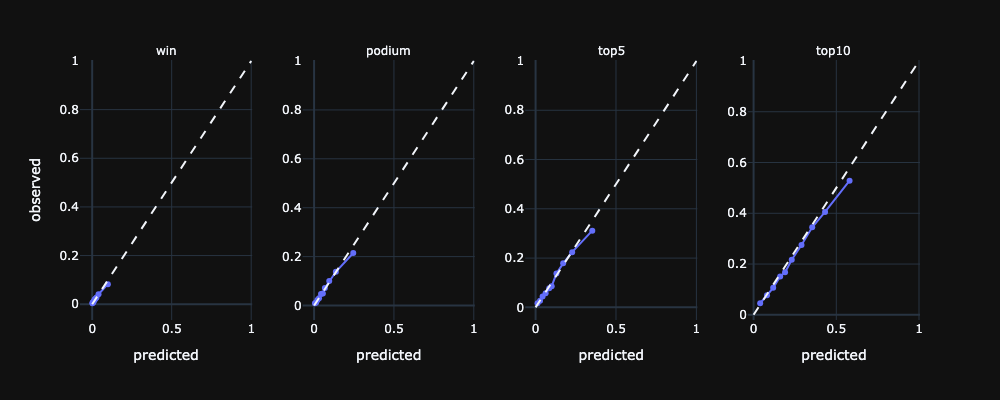

 predicted  observed  nb_rows target
     0.001     0.004     5158    win
     0.003     0.006     5157    win
     0.005     0.007     5157    win
     0.007     0.010     5157    win
     0.011     0.013     5157    win
     0.015     0.019     5157    win
     0.021     0.023     5199    win
     0.027     0.028     5115    win
     0.040     0.041     5157    win
     0.099     0.082     5157    win
     0.005     0.009     5158 podium
     0.013     0.012     5157 podium
     0.021     0.022     5157 podium
     0.031     0.030     5157 podium
     0.043     0.047     5157 podium
     0.055     0.049     5157 podium
     0.067     0.072     5157 podium
     0.095     0.100     5157 podium
     0.136     0.138     5157 podium
     0.245     0.215     5157 podium
     0.012     0.017     5158   top5
     0.028     0.027     5157   top5
     0.044     0.044     5157   top5
     0.062     0.057     5157   top5
     0.085     0.077     5157   top5
     0.100     0.086     5157   top5
 

In [59]:
rows = evaluated_rows(option_2, TUNING_START, TUNING_END)
calibration = []
for target in TARGETS:
    bins = pd.qcut(rows[f"p_{target}"], q=10, duplicates="drop")
    grouped = rows.groupby(bins, observed=True).agg(
        predicted=(f"p_{target}", "mean"), observed=(target, "mean"), nb_rows=(target, "size")
    )
    calibration.append(grouped.reset_index(drop=True).assign(target=target))
calibration = pd.concat(calibration, ignore_index=True)

fig = px.line(
    calibration, x="predicted", y="observed", facet_col="target", markers=True,
    facet_col_spacing=0.06, height=400
)
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line_dash="dash", row="all", col="all")
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

print(calibration.round(3).to_string(index=False))

#### Lecture

Les probabilités sont globalement bien calibrées, mais **les favoris sont surestimés** pour toutes les cibles :

| Cible | Décile le plus haut : prévu | Observé | Surestimation relative |
|---|---|---|---|
| Victoire | 0,099 | 0,082 | environ 20 % |
| Podium | 0,245 | 0,215 | environ 14 % |
| Top 5 | 0,353 | 0,311 | environ 13 % |
| Top 10 | 0,580 | 0,529 | environ 10 % |

Un coureur annoncé à 10 % de chances de victoire gagne en réalité environ 8 fois sur 100. Cela ne change pas l'ordre des listes, mais fausserait les probabilités affichées.

#### Cause probable

Le modèle prévoit chaque coureur séparément, sans savoir qu'une course compte exactement un vainqueur, trois places de podium, cinq de top 5 et dix de top 10. Les sommes des probabilités par course sont donc comparées à ces valeurs.

In [60]:
sums = rows.groupby("race_id")[[f"p_{target}" for target in TARGETS]].sum()
actual = rows.groupby("race_id")[list(TARGETS)].sum()
print(pd.DataFrame({
    "mean_predicted_sum": sums.mean().values,
    "mean_actual_count": actual.mean().values,
}, index=list(TARGETS)).round(3))
print(sums.describe().round(2))

        mean_predicted_sum  mean_actual_count
win                  0.984              0.998
podium               3.072              2.997
top5                 5.226              4.997
top10               10.681              9.996
         p_win  p_podium   p_top5  p_top10
count  1196.00   1196.00  1196.00  1196.00
mean      0.98      3.07     5.23    10.68
std       0.41      1.15     1.89     3.68
min       0.21      0.77     1.42     3.29
25%       0.68      2.21     3.82     7.92
50%       0.94      2.93     4.97    10.22
75%       1.20      3.77     6.37    12.95
max       3.08      8.75    14.32    27.41


#### Lecture

**En moyenne, les sommes sont proches des vraies valeurs**, mais **elles varient énormément d'une course à l'autre** : la somme des probabilités de victoire va de 0,21 à 3,08. Le modèle ignore la taille du peloton : il donne à peu près la même probabilité de victoire à un coureur, qu'il y ait 25 ou 120 engagés. Les favoris des grands pelotons sont ainsi surestimés.

#### Correction retenue

Les probabilités de chaque course sont normalisées : la table coureurs × 5 tranches est ajustée par ajustements successifs des lignes et des colonnes (algorithme de Sinkhorn), pour que chaque coureur ait une somme de 1 et que chaque tranche contienne le bon nombre de coureurs (1 vainqueur, 2 places 2e-3e, 2 places 4e-5e, 5 places 6e-10e, le reste au-delà). Les tranches étant corrigées avant d'être cumulées, les quatre probabilités d'un coureur restent cohérentes.

## 7.7 Normalisation des probabilités par course

### 7.7.1 Calcul

In [61]:
CLASS_BOUNDS = [1, 3, 5, 10]


def normalize_race(probabilities, n_iterations=200, tolerance=1e-9):
    """Sinkhorn scaling: each rider sums to 1, each place class holds its number of riders."""
    n = len(probabilities)
    cumulative = np.minimum(np.array(CLASS_BOUNDS + [n]), n)
    targets = np.diff(np.concatenate([[0], cumulative])).astype(float)
    p = np.clip(probabilities, 1e-12, None)
    for _ in range(n_iterations):
        column_sums = p.sum(axis=0)
        p = p * np.divide(targets, column_sums, out=np.zeros_like(targets), where=column_sums > 0)
        p = p / p.sum(axis=1, keepdims=True)
        if np.abs(p.sum(axis=0) - targets).max() < tolerance:
            break
    return p


def normalize_forecasts(forecasts):
    columns = [f"p_{target}" for target in TARGETS]
    normalized_races = []
    for _, race in forecasts.groupby("race_id"):
        cumulative = race[columns].to_numpy()
        ones = np.ones((len(race), 1))
        classes = np.diff(np.hstack([0 * ones, cumulative, ones]), axis=1).clip(min=0)
        race = race.copy()
        race[columns] = normalize_race(classes).cumsum(axis=1)[:, :4]
        normalized_races.append(race)
    return pd.concat(normalized_races, ignore_index=True)

In [62]:
%%time
option_2_normalized = normalize_forecasts(option_2)

CPU times: user 844 ms, sys: 14.6 ms, total: 858 ms
Wall time: 858 ms


### 7.7.2 Contrôle des sommes

Les sommes doivent valoir exactement 1, 3, 5 et 10 dans chaque course.

In [63]:
rows = evaluated_rows(option_2_normalized, TUNING_START, TUNING_END)
print(rows.groupby("race_id")[[f"p_{target}" for target in TARGETS]].sum().describe().round(3))

        p_win  p_podium  p_top5  p_top10
count  1196.0    1196.0  1196.0   1196.0
mean      1.0       3.0     5.0     10.0
std       0.0       0.0     0.0      0.0
min       1.0       3.0     5.0     10.0
25%       1.0       3.0     5.0     10.0
50%       1.0       3.0     5.0     10.0
75%       1.0       3.0     5.0     10.0
max       1.0       3.0     5.0     10.0


### 7.7.3 Réévaluation

Qualité des probabilités avant et après normalisation, puis écarts course par course des métriques de liste.

In [64]:
methods_lists["option 2 normalized"] = (
    option_2_normalized, {target: f"p_{target}" for target in TARGETS}
)
print(pd.DataFrame({
    "option 2": probability_metrics(option_2),
    "option 2 normalized": probability_metrics(option_2_normalized),
}).round(4))
print()
print(paired_list_table("option 2 normalized", "option 2").to_string(index=False))

                option 2  option 2 normalized
win_logloss       0.1014               0.0993
win_brier         0.0222               0.0220
podium_logloss    0.2253               0.2196
podium_brier      0.0609               0.0597
top5_logloss      0.3195               0.3098
top5_brier        0.0942               0.0916
top10_logloss     0.4806               0.4583
top10_brier       0.1566               0.1485

     selection        metric  difference  std_error  ratio  nb_races
      all_year    win_recall      0.0059     0.0040    1.5      1194
      all_year        win_rr     -0.0003     0.0022   -0.2      1194
      all_year podium_recall      0.0013     0.0021    0.6      1196
      all_year   top5_recall     -0.0013     0.0016   -0.8      1196
      all_year  top10_recall      0.0005     0.0006    0.9      1196
february+march    win_recall      0.0069     0.0156    0.4       144
february+march        win_rr      0.0008     0.0058    0.1       144
february+march podium_recall     

#### Lecture

- **Les sommes sont exactes dans chaque course**, pour un calcul de moins d'une seconde.
- **Les probabilités s'améliorent pour les quatre cibles**, d'autant plus que la cible est large (top 10 : log-loss de 0,481 à 0,458, Brier de 0,157 à 0,149).
- **Les listes ne bougent pas** : tous les écarts restent dans le bruit.

La normalisation est conservée : le modèle retenu devient l'option 2 normalisée.

### 7.7.4 Calibration après normalisation

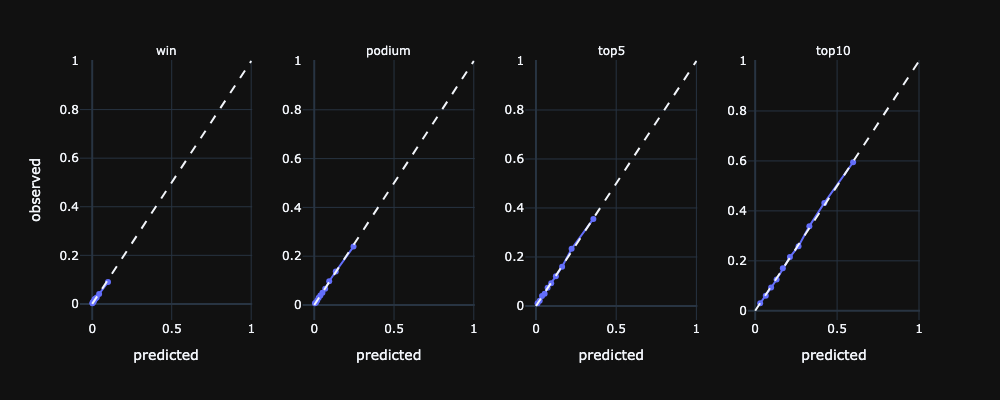

 predicted  observed  nb_rows target
     0.001     0.003     5158    win
     0.003     0.004     5157    win
     0.005     0.006     5157    win
     0.007     0.010     5157    win
     0.010     0.011     5158    win
     0.015     0.019     5156    win
     0.020     0.021     5160    win
     0.028     0.026     5154    win
     0.044     0.041     5157    win
     0.099     0.090     5157    win
     0.005     0.007     5158 podium
     0.011     0.010     5157 podium
     0.019     0.018     5157 podium
     0.028     0.029     5157 podium
     0.038     0.039     5160 podium
     0.051     0.050     5154 podium
     0.069     0.067     5157 podium
     0.094     0.097     5157 podium
     0.135     0.137     5157 podium
     0.246     0.239     5157 podium
     0.010     0.011     5158   top5
     0.023     0.021     5157   top5
     0.038     0.041     5157   top5
     0.054     0.050     5157   top5
     0.073     0.074     5157   top5
     0.095     0.092     5157   top5
 

In [65]:
rows = evaluated_rows(option_2_normalized, TUNING_START, TUNING_END)
calibration = []
for target in TARGETS:
    bins = pd.qcut(rows[f"p_{target}"], q=10, duplicates="drop")
    grouped = rows.groupby(bins, observed=True).agg(
        predicted=(f"p_{target}", "mean"), observed=(target, "mean"), nb_rows=(target, "size")
    )
    calibration.append(grouped.reset_index(drop=True).assign(target=target))
calibration = pd.concat(calibration, ignore_index=True)

fig = px.line(
    calibration, x="predicted", y="observed", facet_col="target", markers=True,
    facet_col_spacing=0.06, height=400
)
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line_dash="dash", row="all", col="all")
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

print(calibration.round(3).to_string(index=False))

#### Lecture

**La calibration est maintenant très bonne** : la surestimation des favoris a presque disparu.

| Cible | Décile le plus haut : prévu | Observé avant normalisation | Observé après |
|---|---|---|---|
| Victoire | 0,099 | 0,082 | 0,090 |
| Podium | 0,246 | 0,215 | 0,239 |
| Top 5 | 0,358 | 0,311 | 0,355 |
| Top 10 | 0,598 | 0,529 | 0,595 |

Pour le podium, le top 5 et le top 10, tous les déciles sont à moins de 0,01 de la diagonale ; seule la victoire garde une légère surestimation des favoris (9,9 % prévu contre 9,0 % observé).

## 7.8 Mesure finale sur 2026

Mesure unique, sur la période de test, du modèle final (option 2 normalisée) face à la baseline : métriques de liste, écarts course par course et qualité des probabilités, puis calibration.

In [66]:
print(pd.DataFrame([
    {"method": name, "selection": selection}
    | list_metrics(*methods_lists[name], TEST_START, TEST_END, months).drop(columns="race_id").mean().round(3).to_dict()
    for name in ["baseline", "option 2 normalized"]
    for selection, months in [("all_year", None), ("february+march", [2, 3])]
]).to_string(index=False))
print()
print(paired_list_table("option 2 normalized", "baseline", TEST_START, TEST_END).to_string(index=False))
print()
print(pd.Series(probability_metrics(option_2_normalized, TEST_START, TEST_END)).round(4))

             method      selection  win_recall  win_rr  podium_recall  top5_recall  top10_recall
           baseline       all_year       0.501   0.195          0.473        0.446         0.724
           baseline february+march       0.480   0.210          0.431        0.395         0.644
option 2 normalized       all_year       0.595   0.236          0.573        0.532         0.749
option 2 normalized february+march       0.467   0.211          0.516        0.464         0.672

     selection        metric  difference  std_error  ratio  nb_races
      all_year    win_recall      0.0941     0.0273    3.4       425
      all_year        win_rr      0.0407     0.0146    2.8       425
      all_year podium_recall      0.0996     0.0139    7.1       425
      all_year   top5_recall      0.0856     0.0097    8.9       425
      all_year  top10_recall      0.0252     0.0049    5.1       425
february+march    win_recall     -0.0133     0.0644   -0.2        75
february+march        win_rr   

#### Calibration sur 2026

Avec environ 425 courses, les déciles sont plus bruités qu'en période de réglage.

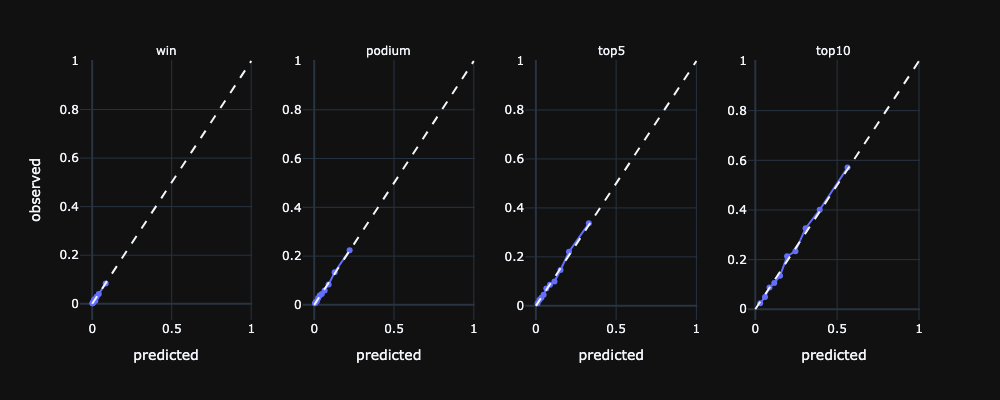

 predicted  observed  nb_rows target
     0.001     0.002     1980    win
     0.003     0.003     1980    win
     0.005     0.005     1979    win
     0.007     0.008     1980    win
     0.010     0.014     1979    win
     0.015     0.019     1980    win
     0.020     0.012     1979    win
     0.028     0.029     1980    win
     0.041     0.040     1979    win
     0.085     0.083     1980    win
     0.005     0.007     1980 podium
     0.010     0.013     1980 podium
     0.017     0.015     1979 podium
     0.025     0.027     1980 podium
     0.035     0.038     1979 podium
     0.047     0.044     1980 podium
     0.065     0.059     1979 podium
     0.090     0.083     1981 podium
     0.128     0.133     1978 podium
     0.222     0.224     1980 podium
     0.010     0.011     1980   top5
     0.022     0.024     1980   top5
     0.034     0.033     1979   top5
     0.048     0.045     1980   top5
     0.065     0.071     1979   top5
     0.088     0.086     1980   top5
 

In [67]:
rows = evaluated_rows(option_2_normalized, TEST_START, TEST_END)
calibration = []
for target in TARGETS:
    bins = pd.qcut(rows[f"p_{target}"], q=10, duplicates="drop")
    grouped = rows.groupby(bins, observed=True).agg(
        predicted=(f"p_{target}", "mean"), observed=(target, "mean"), nb_rows=(target, "size")
    )
    calibration.append(grouped.reset_index(drop=True).assign(target=target))
calibration = pd.concat(calibration, ignore_index=True)

fig = px.line(
    calibration, x="predicted", y="observed", facet_col="target", markers=True,
    facet_col_spacing=0.06, height=400
)
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line_dash="dash", row="all", col="all")
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

print(calibration.round(3).to_string(index=False))

#### Lecture

**Sur l'année, le modèle final bat nettement la baseline sur toutes les listes**, avec des gains plus grands qu'en période de réglage :

| Liste | Baseline | Modèle final | Écart (ratio) |
|---|---|---|---|
| Vainqueur dans la liste de 10 | 0,501 | 0,595 | +0,094 (3,4) |
| Rang réciproque du vainqueur | 0,195 | 0,236 | +0,041 (2,8) |
| Podium dans la liste de 10 | 0,473 | 0,573 | +0,100 (7,1) |
| Top 5 dans la liste de 10 | 0,446 | 0,532 | +0,086 (8,9) |
| Top 10 dans la liste de 20 | 0,724 | 0,749 | +0,025 (5,1) |

- Le vainqueur figure dans la liste « victoire » de 10 coureurs dans 6 courses sur 10, contre 5 sur 10 avec la baseline ; la liste « podium » contient en moyenne 1,7 des 3 coureurs du podium, contre 1,4.
- Au printemps (75 courses), les listes podium, top 5 et top 10 restent nettement meilleures ; pour la victoire, le modèle fait jeu égal avec la baseline, mais la mesure est trop bruitée pour conclure.
- Les probabilités restent fiables sur des données neuves : log-loss et Brier légèrement meilleurs qu'en réglage, et décile des favoris pour la victoire à 8,5 % prévu contre 8,3 % observé.

# 8. Intégration dans le paquet

La chaîne retenue en section 7 est intégrée au paquet `access_it` (cinq commits du 20 novembre 2026). Pour les courses passées, elle s'enchaîne ainsi :

1. `select_forecast_entries` : engagés de chaque course, c'est-à-dire ses classés ;
2. `build_race_eve_features` : forme récente, note OpenSkill et places de chaque engagé, la veille de la course ;
3. `forecast_place_probabilities` : un modèle XGBoost multiclasse par date de course, entraîné sur les 12 mois précédents, puis normalisation par course et rang de chaque coureur pour chaque cible ;
4. `select_evaluated_forecasts`, puis `compute_list_metrics`, `compute_probability_metrics` et `compute_calibration` : métriques des courses évaluées ; `compare_race_metrics` : comparaison course par course.

Les engagés étant une table explicite, la même chaîne servira à prévoir les courses à venir à partir de leurs vraies listes d'engagés.

## 8.1 Modules

`FEATURES` du paquet est importée sous le nom `MODEL_FEATURES`, pour ne pas écraser la variable de la section 5.

In [68]:
from access_it.features.entries import select_forecast_entries
from access_it.features.examples import FEATURES as MODEL_FEATURES
from access_it.features.examples import build_race_eve_features
from access_it.model.evaluation import compare_race_metrics, select_evaluated_forecasts
from access_it.model.forecasts import (
    PROBABILITY_COLUMNS, RANK_COLUMNS, forecast_place_probabilities
)
from access_it.model.target_metrics import (
    LIST_METRICS, compute_calibration, compute_list_metrics, compute_probability_metrics
)

## 8.2 Features à la veille de chaque course

Les engagés commencent au 1er janvier 2023, comme la table des exemples de la section 5. Les features du paquet sont comparées à celles de la table `examples` utilisée en section 7.

In [69]:
%%time
package_entries = select_forecast_entries(races, rankings, LAST_SEASON, "2023-01-01")
package_examples = build_race_eve_features(races, rankings, package_entries)
keys = ["race_id", "rider_id"]
check = package_examples.merge(
    examples[keys + MODEL_FEATURES], on=keys, suffixes=("", "_notebook")
)
print(len(package_examples), len(examples), len(check))
print({f: (check[f] - check[f"{f}_notebook"]).abs().max() for f in MODEL_FEATURES})

77636 77636 77636
{'nb_races_used': np.int64(0), 'nb_top_n': np.int64(0), 'top_n_rate': np.float64(0.0), 'mu': np.float64(0.0), 'sigma': np.float64(0.0), 'best_place': np.float64(0.0), 'mean_place': np.float64(0.0)}
CPU times: user 4.19 s, sys: 108 ms, total: 4.3 s
Wall time: 4.3 s


#### Lecture

Les trois tables comptent 77 636 lignes et les sept features sont identiques : le paquet reproduit exactement la table des exemples de la section 7, en environ 4,3 secondes.

## 8.3 Prévisions

Les courses sont prévues à partir du 1er avril 2023, l'historique d'entraînement étant la table des features complète.

XGBoost tourne sur un seul fil d'exécution (`n_jobs=1`) : sur ces petits modèles, les probabilités sont les mêmes qu'avec tous les cœurs, et le calcul est environ trois fois plus rapide (11,2 s contre 31,4 s sur 20 dates de 2026), les fils passant sinon l'essentiel de leur temps à se coordonner. Ce réglage ménage aussi les ressources gratuites sur lesquelles tournera l'entraînement.

In [70]:
%%time
package_forecasts = forecast_place_probabilities(
    package_examples, package_examples[package_examples["race_date"] >= "2023-04-01"]
)
print(len(package_forecasts), len(option_2_normalized))

74376 74376
CPU times: user 1min 23s, sys: 241 ms, total: 1min 24s
Wall time: 1min 24s


## 8.4 Écart avec la section 7

Les probabilités du paquet sont comparées à celles de l'option 2 normalisée, coureur par coureur.

In [71]:
check = package_forecasts.merge(
    option_2_normalized[keys + PROBABILITY_COLUMNS], on=keys, suffixes=("", "_notebook")
)
differences = pd.DataFrame(
    {p: (check[p] - check[f"{p}_notebook"]).abs() for p in PROBABILITY_COLUMNS}
)
print(differences.describe().round(4))

            p_win    p_podium      p_top5     p_top10
count  74376.0000  74376.0000  74376.0000  74376.0000
mean       0.0022      0.0046      0.0062      0.0091
std        0.0047      0.0080      0.0097      0.0129
min        0.0000      0.0000      0.0000      0.0000
25%        0.0003      0.0007      0.0011      0.0019
50%        0.0008      0.0020      0.0030      0.0050
75%        0.0022      0.0052      0.0074      0.0112
max        0.1569      0.1973      0.2108      0.3630


#### Lecture

Les probabilités diffèrent légèrement : pour la victoire, l'écart médian est de 0,0008, avec des maxima de 0,16 à 0,36 selon la cible. Les features, la cible, les réglages et les fenêtres étant identiques, l'écart vient de **l'ordre des lignes d'entraînement** : XGBoost (méthode `hist`) construit des arbres légèrement différents quand les mêmes lignes sont données dans un autre ordre. La section 7 entraînait sur les exemples triés selon le rang prévu de la baseline ; le paquet trie l'historique par date, course et coureur avant chaque entraînement, pour que ses prévisions ne dépendent pas de l'ordre dans lequel l'historique lui est fourni.

Les deux versions sont deux tirages équivalents du même modèle. Contrôle : un historique mélangé au hasard donne exactement les mêmes probabilités.

In [72]:
%%time
shuffled_forecasts = forecast_place_probabilities(
    package_examples.sample(frac=1, random_state=1),
    package_examples[package_examples["race_date"] >= "2023-04-01"],
)
differences = shuffled_forecasts[PROBABILITY_COLUMNS] - package_forecasts[PROBABILITY_COLUMNS]
print(differences.abs().max())

p_win       0.0
p_podium    0.0
p_top5      0.0
p_top10     0.0
dtype: float64
CPU times: user 1min 24s, sys: 292 ms, total: 1min 24s
Wall time: 1min 24s


## 8.5 Mesure finale sur 2026

La baseline, qui ne fournit qu'un rang prévu, est évaluée en recopiant ce rang dans les quatre colonnes de rang.

In [73]:
package_evaluated = select_evaluated_forecasts(package_forecasts, TEST_START, TEST_END)
package_lists = compute_list_metrics(package_evaluated)
baseline_ranks = baseline.assign(**{rank: baseline["predicted_rank"] for rank in RANK_COLUMNS})
baseline_lists = compute_list_metrics(
    select_evaluated_forecasts(baseline_ranks, TEST_START, TEST_END)
)
print(pd.DataFrame({
    "model": summarize_metrics(package_lists, LIST_METRICS).set_index("metric")["mean"],
    "baseline": summarize_metrics(baseline_lists, LIST_METRICS).set_index("metric")["mean"],
}).round(3))
print()
comparison = compare_race_metrics(package_lists, baseline_lists, LIST_METRICS)
print(comparison.round(4).to_string(index=False))

                     model  baseline
metric                              
win_recall_at_10     0.605     0.501
win_rr_at_10         0.237     0.195
podium_recall_at_10  0.570     0.473
top5_recall_at_10    0.534     0.446
top10_recall_at_20   0.747     0.724

             metric  difference  std_error  ratio  nb_races
   win_recall_at_10      0.1035     0.0276 3.7487       425
       win_rr_at_10      0.0418     0.0148 2.8292       425
podium_recall_at_10      0.0973     0.0138 7.0365       425
  top5_recall_at_10      0.0880     0.0101 8.7208       425
 top10_recall_at_20      0.0233     0.0050 4.6581       425


In [74]:
print(compute_probability_metrics(package_evaluated).round(4).to_string(index=False))

target  log_loss  brier  nb_rows
   win    0.0926 0.0204    19796
podium    0.2083 0.0559    19796
  top5    0.2952 0.0861    19796
 top10    0.4386 0.1411    19796


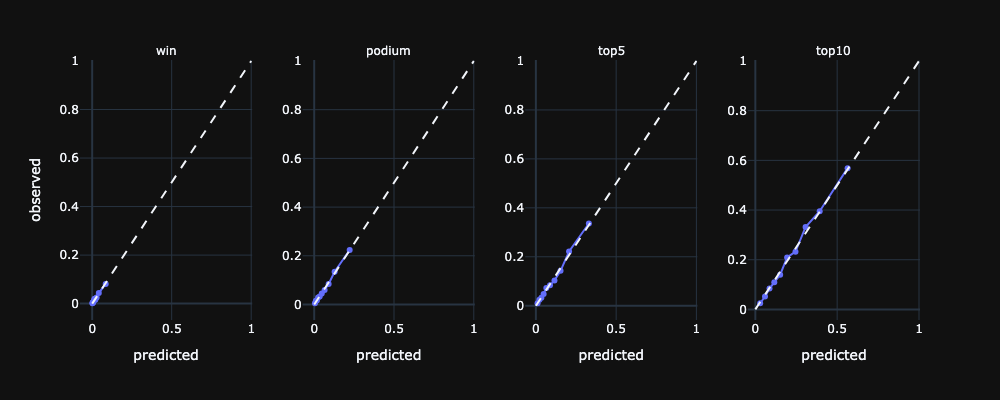

In [75]:
calibration = compute_calibration(package_evaluated)
fig = px.line(
    calibration, x="predicted", y="observed", facet_col="target", markers=True,
    facet_col_spacing=0.06, height=400
)
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line_dash="dash", row="all", col="all")
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

#### Lecture

Sur les 425 courses de 2026, le modèle du paquet bat nettement la baseline sur toutes les listes :

| Liste | Baseline | Modèle du paquet | Écart (ratio) |
|---|---|---|---|
| Vainqueur dans la liste de 10 | 0,501 | 0,605 | +0,104 (3,7) |
| Rang réciproque du vainqueur | 0,195 | 0,237 | +0,042 (2,8) |
| Podium dans la liste de 10 | 0,473 | 0,570 | +0,097 (7,0) |
| Top 5 dans la liste de 10 | 0,446 | 0,534 | +0,088 (8,7) |
| Top 10 dans la liste de 20 | 0,724 | 0,747 | +0,023 (4,7) |

- Les écarts avec la section 7 (0,595, 0,236, 0,573, 0,532 et 0,749) restent bien inférieurs aux erreurs types : la conclusion est la même.
- Les probabilités restent bien calibrées : pour la victoire, le décile des favoris est prévu à 8,5 % et observé à 8,1 % ; tous les déciles sont proches de la diagonale.

**Ces valeurs deviennent la référence** des évaluations futures, puisqu'elles sont produites par le code du paquet.

# 9. Conclusion

**Modèle retenu :** XGBoost multiclasse sur les tranches de places (victoire, 2e-3e, 4e-5e, 6e-10e, au-delà), avec la forme récente, la note OpenSkill et les places récentes comme features, une fenêtre d'entraînement de 12 mois, 200 arbres de profondeur 3 et une normalisation des probabilités par course. Il fournit pour chaque course le rang et la probabilité de chaque coureur pour la victoire, le podium, le top 5 et le top 10. Il est intégré au paquet `access_it` (section 8).

**Résultats sur 2026** (données jamais utilisées pour choisir, valeurs du paquet) : face à la baseline, le vainqueur figure dans la liste de 10 dans 60 % des courses au lieu de 50 %, les listes podium et top 5 contiennent 9 à 10 points de plus des bons coureurs, et les probabilités sont bien calibrées.

**Enseignements :**

- la forme récente seule est une base solide, mais faible en début de saison ;
- la note OpenSkill, insuffisante seule, apporte une information complémentaire comme feature ;
- un modèle non linéaire (XGBoost) est nécessaire pour bien repérer le haut du classement ;
- des probabilités justes demandent de tenir compte de la composition de chaque course, d'où la normalisation par course ;
- XGBoost dépend de l'ordre des lignes d'entraînement : le paquet le fixe pour que les prévisions soient reproductibles.

**Limite :** les engagés d'une course passée sont ses classés (abandons absents) ; la prévision des courses à venir nécessitera les vraies listes d'engagés.

**Suite :** prévision des courses à venir à partir des vraies listes d'engagés, puis affichage dans le dashboard.